# Assignment 2510

#### Abdalrahman Mohammed & Casper Aborres

### Project A: Enhancing the LSTM-VAE for Time-Series Anomaly Detection

#### Importing Necessary Libraries


In [19]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

import tensorflow as tf
from tensorflow.keras import backend as K
from tensorflow.keras.layers import Input, LSTM, RepeatVector, Dense, Lambda
from tensorflow.keras import layers, models
from tensorflow.keras.models import Model
from tensorflow.keras import losses


#### Data Preprocessing and Windowing

In [20]:
def get_raw_data():
    # 1. Load the binary data and reshape to 13 columns as per Lab1
    data = np.fromfile("data_lab1/sample_data.dat").reshape(419, 13)
    return data

def get_windowed_data(data, timesteps=3):
    # 2. Apply the sliding window logic
    dataX = []
    for i in range(len(data) - timesteps - 1):
        x_window = data[i:(i + timesteps), :]
        dataX.append(x_window)
    return np.array(dataX)

# --- EXECUTION ---
raw_data = get_raw_data()
windowed_data = get_windowed_data(raw_data)

In [21]:
# Create generic headers for the 13 features
headers = [f"Sensor_{i+1}" for i in range(13)]

# A. Show Table (First 5 Rows of the raw data)
print("--- FIRST 5 ROWS OF RAW DATA (13 FEATURES) ---")
df = pd.DataFrame(raw_data, columns=headers)
print(df.head(5))

# B. Show 5 Samples of Windowed Data (Each sample is 3 timesteps)
print("\n--- FIRST 5 WINDOWED SAMPLES (FOR LSTM INPUT) ---")
for i in range(5):
    print(f"\nSample {i+1} (Shape: {windowed_data[i].shape}):")
    # Displaying each sample as a small dataframe for clarity
    sample_df = pd.DataFrame(windowed_data[i], columns=headers)
    sample_df.index = [f"t-{2-j}" for j in range(3)] # Labeling time steps
    print(sample_df)

--- FIRST 5 ROWS OF RAW DATA (13 FEATURES) ---
   Sensor_1  Sensor_2  Sensor_3  Sensor_4  Sensor_5  Sensor_6  Sensor_7  \
0  0.649313  0.896542   0.27325   0.22933  0.872118  0.142583  0.285714   
1  0.649313  0.896542   0.27325   0.22933  0.872118  0.142583  0.285714   
2  0.649313  0.896542   0.27325   0.22933  0.872118  0.142583  0.357143   
3  0.649313  0.896542   0.27325   0.22933  0.872118  0.142583  0.357143   
4  0.649313  0.896542   0.27325   0.22933  0.872118  0.142583  0.357143   

   Sensor_8  Sensor_9  Sensor_10  Sensor_11  Sensor_12  Sensor_13  
0  0.318182  0.853846   0.617647   0.293478   0.398936   0.296296  
1  0.318182  0.961538   0.715686   0.344203   0.414894   0.259259  
2  0.369318  1.000000   0.833333   0.449275   0.505319   0.277778  
3  0.477273  0.792308   0.921569   0.507246   0.648936   0.277778  
4  0.517045  0.707692   0.980392   0.489130   0.675532   0.296296  

--- FIRST 5 WINDOWED SAMPLES (FOR LSTM INPUT) ---

Sample 1 (Shape: (3, 13)):
     Sensor_1  

#### Defining the Beta Variational Autoencoder Architecture

In [22]:
class VAELayer(layers.Layer):
    def __init__(self, beta=1.0, **kwargs):
        super(VAELayer, self).__init__(**kwargs)
        self.beta = beta

    def call(self, inputs):
        z_mean, z_log_sigma = inputs

        # Calculate and add weighted KL divergence
        kl_loss = -0.5 * tf.reduce_mean(1 + z_log_sigma - tf.square(z_mean)- tf.exp(z_log_sigma))
        self.add_loss(self.beta * kl_loss)

        # Reparameterization trick
        epsilon = tf.random.normal(shape=tf.shape(z_mean))
        return z_mean + tf.exp(z_log_sigma / 2) * epsilon


# Model parameters
intermediate_dim = 32
latent_dim = 100
batch_size = 1
timesteps = 3
input_dim = 13
beta = 1.0
# --- ENCODER ---
inputs = layers.Input(shape=(timesteps, input_dim))
h = layers.LSTM(intermediate_dim)(inputs)
z_mean = layers.Dense(latent_dim)(h)
z_log_sigma = layers.Dense(latent_dim)(h)

# Sample latent vector and add weighted KL loss
z = VAELayer(beta=beta)([z_mean, z_log_sigma])

# --- DECODER ---
decoder_h = layers.LSTM(intermediate_dim, return_sequences=True)
decoder_mean = layers.LSTM(input_dim, return_sequences=True)

h_decoded = layers.RepeatVector(timesteps)(z)
h_decoded = decoder_h(h_decoded)
x_decoded_mean = decoder_mean(h_decoded)

# --- MODEL ---
vae = models.Model(inputs, x_decoded_mean)

# Use MSE loss and track reconstruction error (KL is added by VAELayer)
vae.compile(optimizer="adam", loss="mse", metrics=[tf.keras.metrics.MeanSquaredError(name="reconstruction_mse")])

# For Inference: Encoder and Generator
encoder = models.Model(inputs, [z_mean, z_log_sigma])

decoder_input = layers.Input(shape=(latent_dim,))
_h_decoded = layers.RepeatVector(timesteps)(decoder_input)
_h_decoded = decoder_h(_h_decoded)
_x_decoded_mean = decoder_mean(_h_decoded)
generator = models.Model(decoder_input, _x_decoded_mean)


print("Model built and compiled successfully.")

Model built and compiled successfully.


In [23]:
vae.summary()

# Encoder summary
encoder.summary()

# Generator (decoder) summary
generator.summary()

Model: "functional_24"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_16      │ (None, 3, 13)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_24 (LSTM)      │ (None, 32)        │      5,888 │ input_layer_16[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_16 (Dense)    │ (None, 100)       │      3,300 │ lstm_24[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_17 (Dense)    │ (None, 100)       │      3,300 │ lstm_24[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ vae_layer_8         │ (None, 100)       │          0 │ dense_16[0][0],   │
│ (VAELayer)          │                   │            │ dense_17[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ repeat_vector_16    │ (None, 3, 100)    │          0 │ vae_layer_8[0][0] │
│ (RepeatVector)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_25 (LSTM)      │ (None, 3, 32)     │     17,024 │ repeat_vector_16… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_26 (LSTM)      │ (None, 3, 13)     │      2,392 │ lstm_25[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 31,904 (124.62 KB)

 Trainable params: 31,904 (124.62 KB)

 Non-trainable params: 0 (0.00 B)

Model: "functional_25"

... (5 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_17 (InputLayer)     │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_vector_17 (RepeatVector) │ (None, 3, 100)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_25 (LSTM)                  │ (None, 3, 32)          │        17,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_26 (LSTM)                  │ (None, 3, 13)          │         2,392 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,416 (75.84 KB)

 Trainable params: 19,416 (75.84 KB)

 Non-trainable params: 0 (0.00 B)

### Training

In [24]:
beta_values = [0.1, 1.0, 5.0]

results = []
histories = {}
errors = {}

# Split the data by time
x = windowed_data.astype("float32")
split1 = int(len(x) * 0.6)
split2 = int(len(x) * 0.8)

# Prevent overlap between splits
gap = timesteps - 1
x_train = x[:split1]
x_cal = x[split1 + gap:split2]
x_test = x[split2 + gap:]

print("Training data:", x_train.shape)
print("Calibration data:", x_cal.shape)
print("Testing data:", x_test.shape)


for beta in beta_values:

    print(f"\nTraining beta = {beta}")
    tf.keras.utils.set_random_seed(69)

    # --- ENCODER ---
    inputs = layers.Input(shape=(timesteps, input_dim))
    h = layers.LSTM(intermediate_dim)(inputs)
    z_mean = layers.Dense(latent_dim)(h)
    z_log_sigma = layers.Dense(latent_dim)(h)

    # Sample latent vector and add weighted KL loss
    z = VAELayer(beta=beta)([z_mean, z_log_sigma])

    # --- DECODER ---
    decoder_h = layers.LSTM(intermediate_dim, return_sequences=True)
    decoder_mean = layers.LSTM(input_dim, return_sequences=True)

    h_decoded = layers.RepeatVector(timesteps)(z)
    h_decoded = decoder_h(h_decoded)
    x_decoded_mean = decoder_mean(h_decoded)

    # --- MODEL ---
    vae = models.Model(inputs, x_decoded_mean)

    # Use MSE loss and track reconstruction error (KL is added by VAELayer)
    vae.compile(optimizer="adam", loss="mse", metrics=[tf.keras.metrics.MeanSquaredError(name="reconstruction_mse")])

    # For Inference: Encoder and Generator
    encoder = models.Model(inputs, [z_mean, z_log_sigma])

    decoder_input = layers.Input(shape=(latent_dim,))
    _h_decoded = layers.RepeatVector(timesteps)(decoder_input)
    _h_decoded = decoder_h(_h_decoded)
    _x_decoded_mean = decoder_mean(_h_decoded)
    generator = models.Model(decoder_input, _x_decoded_mean)

    # Training
    history = vae.fit(x_train, x_train, epochs=20, batch_size=batch_size, verbose=1)
    histories[beta] = history.history

    z_mean, z_log_sigma = encoder.predict(x_test, verbose=0)
    preds = generator.predict(z_mean, verbose=0)

    # Reconstruction MSE
    mse_error = np.mean(np.square(x_test - preds), axis=(1, 2))
    mse = np.mean(mse_error)

    # Unweighted KL divergence
    kl_loss = -0.5 * np.mean(1 + z_log_sigma - np.square(z_mean) - np.exp(z_log_sigma))

    # Calibration errors
    z_cal, _ = encoder.predict(x_cal, verbose=0)
    cal_preds = generator.predict(z_cal, verbose=0)
    cal_errors = np.mean(np.square(x_cal - cal_preds), axis=(1, 2))

    errors[beta] = {"calibration": cal_errors, "test": mse_error}
    results.append({"Beta": beta, "Reconstruction MSE": mse, "KL Loss": kl_loss})

results_df = pd.DataFrame(results)
display(results_df)

Training data: (249, 3, 13)
Calibration data: (81, 3, 13)
Testing data: (81, 3, 13)

Training beta = 0.1


Epoch 1/20
249/249 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - loss: 0.1081 - reconstruction_mse: 0.0972
Epoch 2/20
249/249 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.0447 - reconstruction_mse: 0.0358
Epoch 3/20
249/249 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.0367 - reconstruction_mse: 0.0295
Epoch 4/20
249/249 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.0302 - reconstruction_mse: 0.0232
Epoch 5/20
249/249 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 0.0277 - reconstruction_mse: 0.0204
Epoch 6/20
249/249 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.0249 - reconstruction_mse: 0.0190
Epoch 7/20
249/249 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.0240 - reconstruction_mse: 0.0183
Epoch 8/20
249/249 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.0231 - reconstruction_mse: 0.0177
Epoch 9/20
249/249 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.0232 - reconstruction_mse: 0.0176
Epoch 10/20
249/249 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.0231 - reconstruction_mse: 0.0179
Epoch 11/20
249/249 ━━━━━━━━━━━━━━━━━━

,Beta,Reconstruction MSE,KL Loss
0,0.1,0.016728,0.049542
1,1.0,0.024170,0.004897
2,5.0,0.044906,0.000021


#### Evaluation and Anomaly Detection


Beta = 0.1
Static threshold: 0.049267
Static anomalies: 0
Dynamic anomalies: 0


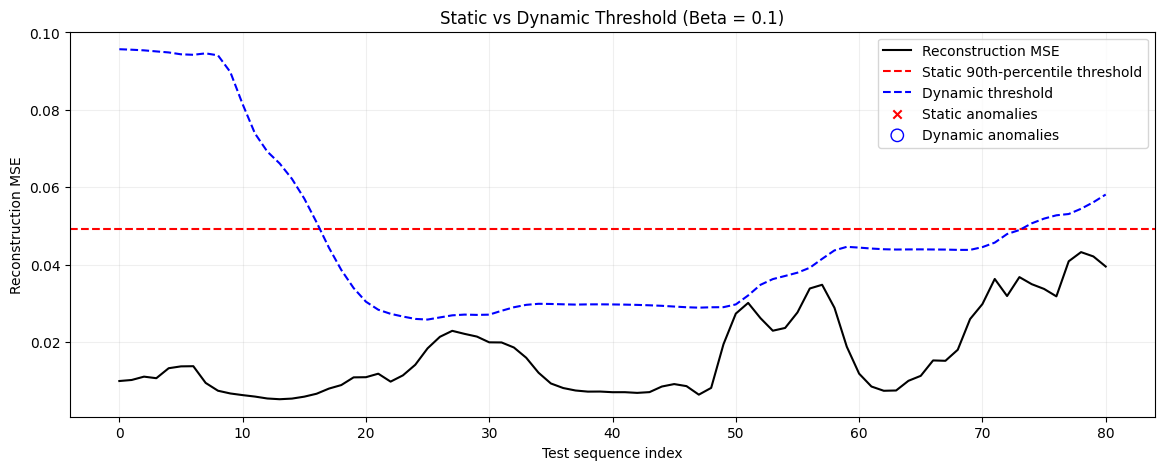


Beta = 1.0
Static threshold: 0.051419
Static anomalies: 3
Dynamic anomalies: 1


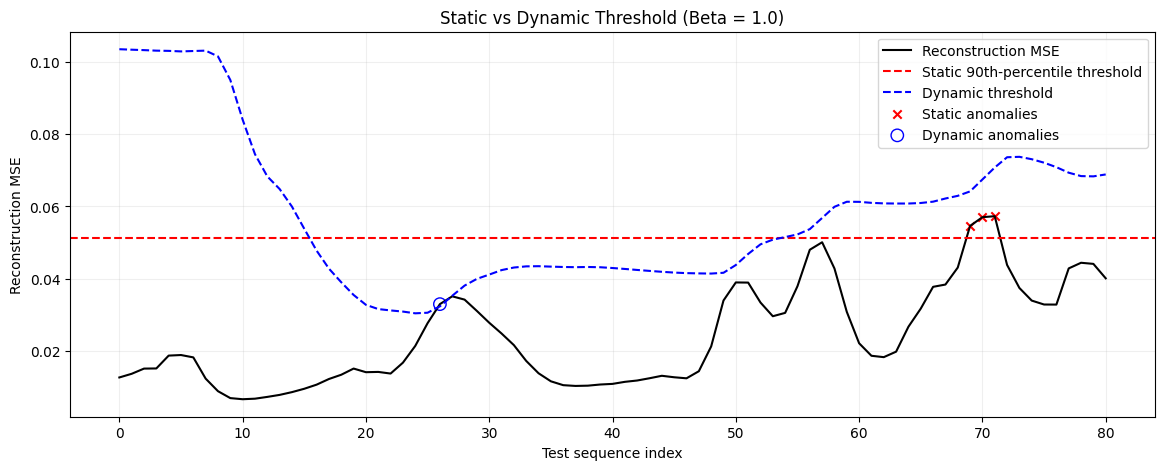


Beta = 5.0
Static threshold: 0.060010
Static anomalies: 18
Dynamic anomalies: 5


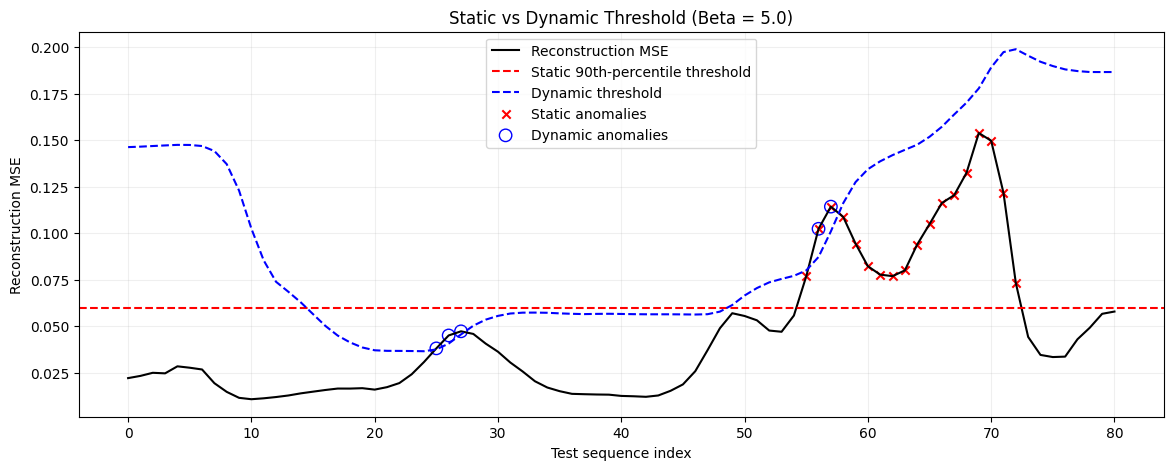

,Beta,Static anomalies,Dynamic anomalies
0,0.1,0,0
1,1.0,3,1
2,5.0,18,5


In [25]:
window_size = 30
k = 3

threshold_results = []

for beta in beta_values:

    cal_errors = errors[beta]["calibration"]
    mse_error = errors[beta]["test"]

    # Static threshold
    static_threshold = np.percentile(cal_errors, 90)
    static_anomalies = mse_error > static_threshold

    # Combine errors
    error_series = pd.Series(np.concatenate([cal_errors, mse_error]))

    # Rolling statistics
    rolling_mean = error_series.shift(1).rolling(window=window_size).mean()
    rolling_std = error_series.shift(1).rolling(window=window_size).std()

    # Dynamic threshold
    dynamic_threshold = rolling_mean + k * rolling_std
    dynamic_threshold = dynamic_threshold.iloc[len(cal_errors):].to_numpy()

    # Detect anomalies
    dynamic_anomalies = mse_error > dynamic_threshold

    print(f"\nBeta = {beta}")
    print(f"Static threshold: {static_threshold:.6f}")
    print("Static anomalies:", np.sum(static_anomalies))
    print("Dynamic anomalies:", np.sum(dynamic_anomalies))

    threshold_results.append({"Beta": beta, "Static anomalies": np.sum(static_anomalies), "Dynamic anomalies": np.sum(dynamic_anomalies)})

    plt.figure(figsize=(14, 5))
    plt.plot(mse_error, color="black", label="Reconstruction MSE")
    plt.axhline(y=static_threshold, color="red", linestyle="--", label="Static 90th-percentile threshold")
    plt.plot(dynamic_threshold, color="blue", linestyle="--", label="Dynamic threshold")

    static_idx = np.where(static_anomalies)[0]
    dynamic_idx = np.where(dynamic_anomalies)[0]

    plt.scatter(static_idx, mse_error[static_idx], color="red", marker="x", label="Static anomalies")
    plt.scatter(dynamic_idx,mse_error[dynamic_idx],color="blue", facecolors="none", s=80, label="Dynamic anomalies")

    plt.title(f"Static vs Dynamic Threshold (Beta = {beta})")
    plt.xlabel("Test sequence index")
    plt.ylabel("Reconstruction MSE")
    plt.legend()
    plt.grid(alpha=0.2)
    plt.show()


display(pd.DataFrame(threshold_results))

#### Plot reconstruction MSE vs. KL loss


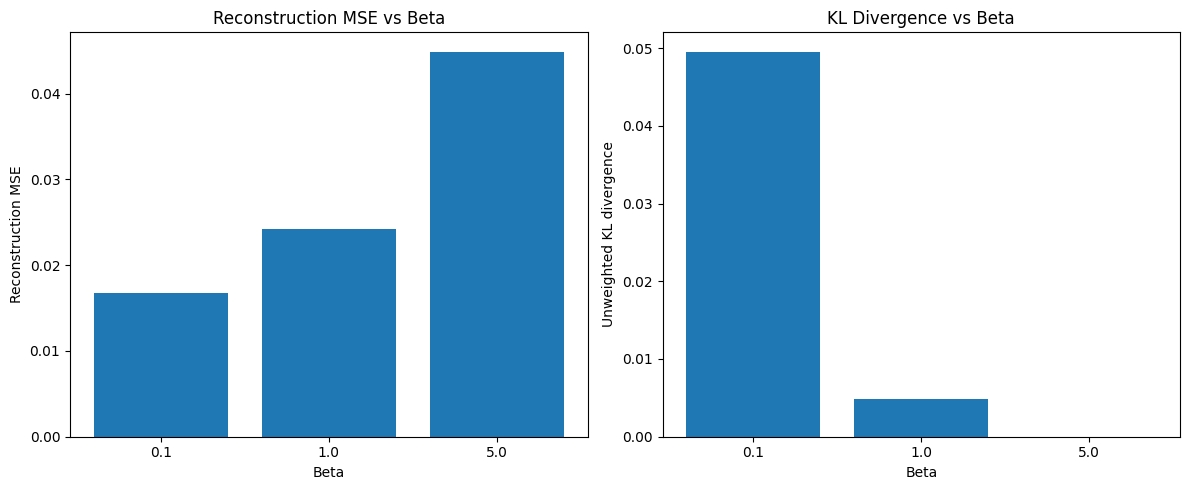

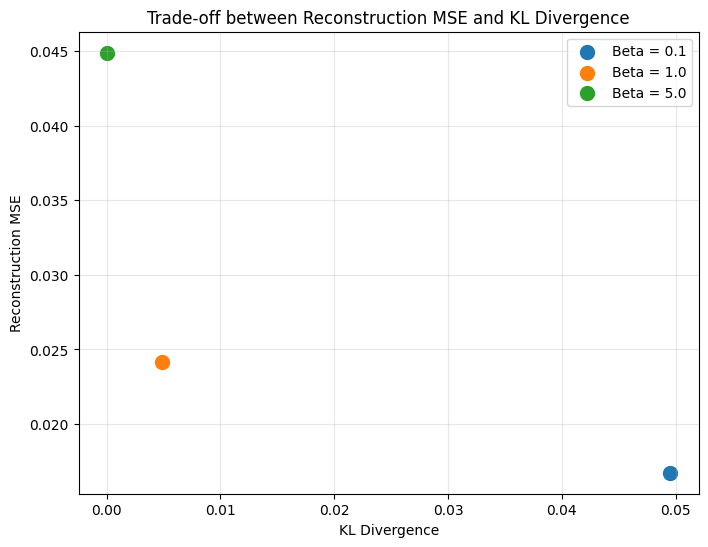

,Beta,Reconstruction MSE,KL Loss
0,0.1,0.016728,0.049542
1,1.0,0.024170,0.004897
2,5.0,0.044906,0.000021


In [26]:
# Compare MSE and KL loss
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
beta_labels = results_df["Beta"].astype(str)

ax1.bar(beta_labels,results_df["Reconstruction MSE"])
ax1.set_title("Reconstruction MSE vs Beta")
ax1.set_xlabel("Beta")
ax1.set_ylabel("Reconstruction MSE")

ax2.bar(beta_labels, results_df["KL Loss"])
ax2.set_title("KL Divergence vs Beta")
ax2.set_xlabel("Beta")
ax2.set_ylabel("Unweighted KL divergence")

plt.tight_layout()
plt.show()


# MSE vs KL divergence
plt.figure(figsize=(8, 6))

for _, row in results_df.iterrows():
    plt.scatter(row["KL Loss"], row["Reconstruction MSE"], s=100, label=f'Beta = {row["Beta"]}')

plt.xlabel("KL Divergence")
plt.ylabel("Reconstruction MSE")
plt.title("Trade-off between Reconstruction MSE and KL Divergence")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

display(results_df)

#### Plot the training progress

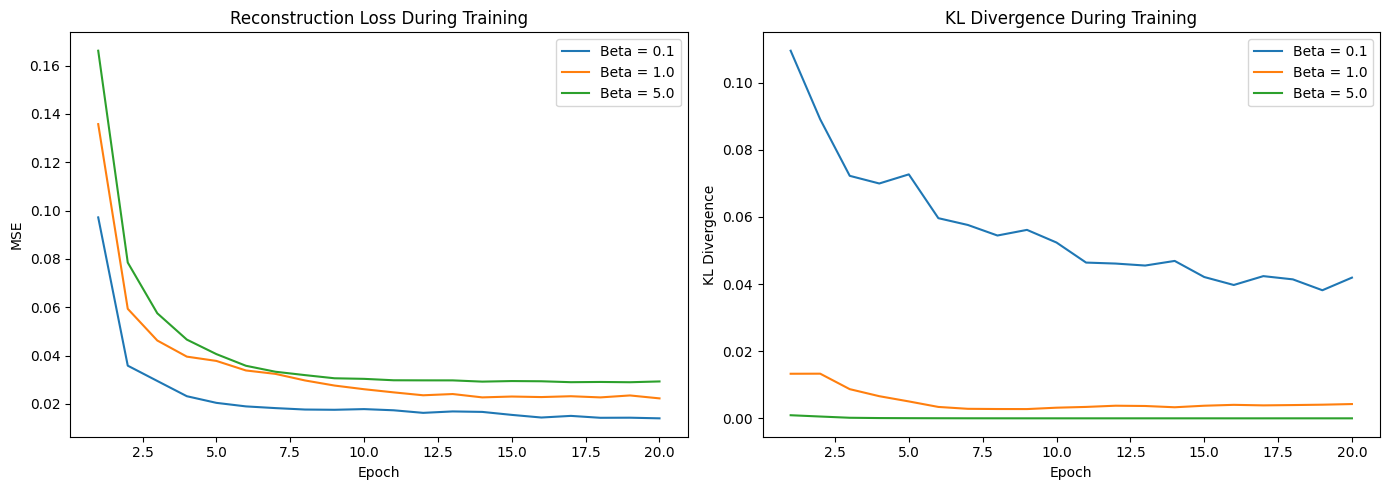

In [27]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

for beta in beta_values:

    history = histories[beta]
    reconstruction_loss = np.array(history["reconstruction_mse"])
    total_loss = np.array(history["loss"])

    kl_loss = (total_loss - reconstruction_loss) / beta

    epochs_range = range(1, len(total_loss) + 1)

    ax1.plot(epochs_range, reconstruction_loss, label=f"Beta = {beta}")
    ax2.plot(epochs_range, kl_loss, label=f"Beta = {beta}" )

ax1.set_title("Reconstruction Loss During Training")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("MSE")
ax1.legend()

ax2.set_title("KL Divergence During Training")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("KL Divergence")
ax2.legend()

plt.tight_layout()
plt.show()

### Project B: SeqGAN Diagnostic Evaluation Pipeline

#### Setup

Start here to run Project B. The default setup uses the downloaded Colab results locally and the `save/` folder in Colab. Leave the switches off and run the cells in order to show the saved results. Keep the full results folder so the notebook can read the saved logs, samples, and checkpoints.

The Lab 2 baseline uses a generator learning rate of 0.01 and 16 Monte Carlo rollouts. Each variant changes one of these settings. This notebook runs 50 adversarial rounds, with one generator update per round. To train, set `RUN_SEQGAN_ADVERSARIAL = True`. The training launchers use `pretrained.ckpt` and its matching `real_data.txt` when pretraining is disabled. Running the experiments creates additional folders in the save folder for the logs, generated samples, and checkpoints.

To continue an interrupted adversarial run, set `RESUME_SEQGAN_TRAINING = True`, keep pretraining off, and use the same save folder and training settings. Set `RESUME_SEQGAN_TRAINING = False` for a fresh run.

To run in Colab, change the path in `os.chdir(...)` to the Drive folder where your notebook and `save/` folder are stored. For a complete new run from scratch, put `target_params_py3.pkl` in the selected save folder and set both `RUN_SEQGAN_PRETRAINING` and `RUN_SEQGAN_ADVERSARIAL` to `True`. Pretraining will generate `real_data.txt` and save `pretrained.ckpt`. Leave resume off for this run.


In [1]:
import os
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from pathlib import Path

# The default workflow displays the saved results.
RUN_SEQGAN_PRETRAINING = False  # Create the Oracle training data and pretrained checkpoint.
RUN_SEQGAN_ADVERSARIAL = False  # Train the baseline and the two hyperparameter variants.
RESUME_SEQGAN_TRAINING = False  # Resume from saved adversarial progress when training.
REGENERATE_ORACLE_REFERENCE = False  # Draw a fresh reference sample from the Oracle.
RUN_TEMPERATURE_COMPARISON = False  # Repeat sampling at both temperatures.

try:
    from google.colab import drive
except ModuleNotFoundError:
    drive = None

if drive is not None:
    drive.mount('/content/drive')
    os.chdir('/content/drive/MyDrive/Colab Notebooks/Ass2510')  # Set your project directory on Google Drive.
    SAVE_DIR = Path('save')
else:
    downloaded_save = Path('save-20261120T130756Z-1-001')  # Change this if your results folder has a different name.
    SAVE_DIR = downloaded_save if downloaded_save.is_dir() else Path('save')

EVALUATION_DIR = SAVE_DIR / 'evaluation'
BASELINE_RUNS_DIR = SAVE_DIR / 'adversarial-progress'
EXPERIMENT_RUNS_DIR = SAVE_DIR / 'hyperparameter-experiments'
EXPERIMENT_LOG = SAVE_DIR / 'experiment-log.txt'
ORACLE_PARAMS = SAVE_DIR / 'target_params_py3.pkl'

if not SAVE_DIR.is_dir():
    raise FileNotFoundError(f'Could not find the save folder: {SAVE_DIR.resolve()}')
if not ORACLE_PARAMS.is_file():
    raise FileNotFoundError(f'Could not find the Oracle parameters: {ORACLE_PARAMS.resolve()}')
print('Using SeqGAN files from:', SAVE_DIR.resolve())

Using SeqGAN files from: C:\Users\caspe\Documents\GitHub\Abdalrahman_Mohammed_Casper_Aborres\save-20261120T130756Z-1-001


In [2]:
import os
import random
import numpy as np
import tensorflow.compat.v1 as tf
tf.disable_v2_behavior()
from tensorflow.python.ops import tensor_array_ops

#########################################################################################
#  Generator  Hyper-parameters
######################################################################################
EMB_DIM = 32 # embedding dimension
HIDDEN_DIM = 32 # hidden state dimension of lstm cell
SEQ_LENGTH = 20 # sequence length
START_TOKEN = 0
PRE_EPOCH_NUM = 60 # supervise (maximum likelihood estimation) epochs -(Original 120)
SEED = 88
BATCH_SIZE = 64

#########################################################################################
#  Discriminator  Hyper-parameters
#########################################################################################
dis_embedding_dim = 64
dis_filter_sizes = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 15, 20]
dis_num_filters = [100, 200, 200, 200, 200, 100, 100, 100, 100, 100, 160, 160]
dis_dropout_keep_prob = 0.75
dis_l2_reg_lambda = 0.2
dis_batch_size = 64

#########################################################################################
#  Basic Training Parameters
#########################################################################################
TOTAL_BATCH = 50  # adversarial rounds (original: 200). 50 is enough to see the NLL drop below the MLE level, at ~1/4 of the time
positive_file = str(SAVE_DIR / 'real_data.txt')
negative_file = str(SAVE_DIR / 'generator_sample.txt')
eval_file = str(SAVE_DIR / 'eval_file.txt')
PRETRAIN_CKPT = str(SAVE_DIR / 'pretrained.ckpt')   # model after generator + discriminator pre-training
FINAL_CKPT = str(SAVE_DIR / 'seqgan_final.ckpt')    # model after adversarial training
generated_num = 10000


Instructions for updating:
non-resource variables are not supported in the long term


##### Oracle model

The Lab 2 target LSTM provides the training sequences and scores generated samples.

In [3]:
def TARGET_LSTM(num_emb, batch_size, emb_dim, hidden_dim, sequence_length, start_token, params):

    state = {}

    state['num_emb'] = num_emb
    state['batch_size'] = batch_size
    state['emb_dim'] = emb_dim
    state['hidden_dim'] = hidden_dim
    state['sequence_length'] = sequence_length
    state['start_token'] = tf.constant([start_token] * batch_size, dtype=tf.int32)
    state['g_params'] = []
    state['temperature'] = 1.0
    state['params'] = params

    tf.set_random_seed(66)

    def init_matrix(shape):
        return tf.random_normal(shape, stddev=1.0)

    def create_recurrent_unit(params):
        Wi = tf.Variable(state['params'][1])
        Ui = tf.Variable(state['params'][2])
        bi = tf.Variable(state['params'][3])

        Wf = tf.Variable(state['params'][4])
        Uf = tf.Variable(state['params'][5])
        bf = tf.Variable(state['params'][6])

        Wog = tf.Variable(state['params'][7])
        Uog = tf.Variable(state['params'][8])
        bog = tf.Variable(state['params'][9])

        Wc = tf.Variable(state['params'][10])
        Uc = tf.Variable(state['params'][11])
        bc = tf.Variable(state['params'][12])

        params.extend([Wi, Ui, bi, Wf, Uf, bf, Wog, Uog, bog, Wc, Uc, bc])

        def unit(x, hidden_memory_tm1):
            previous_hidden_state, c_prev = tf.unstack(hidden_memory_tm1)

            i = tf.sigmoid(tf.matmul(x, Wi) + tf.matmul(previous_hidden_state, Ui) + bi)
            f = tf.sigmoid(tf.matmul(x, Wf) + tf.matmul(previous_hidden_state, Uf) + bf)
            o = tf.sigmoid(tf.matmul(x, Wog) + tf.matmul(previous_hidden_state, Uog) + bog)

            c_ = tf.nn.tanh(tf.matmul(x, Wc) + tf.matmul(previous_hidden_state, Uc) + bc)
            c = f * c_prev + i * c_
            current_hidden_state = o * tf.nn.tanh(c)

            return tf.stack([current_hidden_state, c])

        return unit

    def create_output_unit(params):
        Wo = tf.Variable(state['params'][13])
        bo = tf.Variable(state['params'][14])

        params.extend([Wo, bo])

        def unit(hidden_memory_tuple):
            hidden_state, c_prev = tf.unstack(hidden_memory_tuple)
            logits = tf.matmul(hidden_state, Wo) + bo
            return logits

        return unit

    with tf.variable_scope('generator'):
        state['g_embeddings'] = tf.Variable(state['params'][0])
        state['g_params'].append(state['g_embeddings'])
        state['g_recurrent_unit'] = create_recurrent_unit(state['g_params'])
        state['g_output_unit'] = create_output_unit(state['g_params'])

    state['x'] = tf.placeholder(tf.int32, shape=[batch_size, sequence_length])

    with tf.device("/cpu:0"):
        state['processed_x'] = tf.transpose(
            tf.nn.embedding_lookup(state['g_embeddings'], state['x']),
            perm=[1, 0, 2]
        )

    h0 = tf.zeros([batch_size, hidden_dim])
    state['h0'] = tf.stack([h0, h0])

    gen_o = tensor_array_ops.TensorArray(dtype=tf.float32, size=sequence_length)
    gen_x = tensor_array_ops.TensorArray(dtype=tf.int32, size=sequence_length)

    def _g_recurrence(i, x_t, h_tm1, gen_o, gen_x):
        h_t = state['g_recurrent_unit'](x_t, h_tm1)
        o_t = state['g_output_unit'](h_t)

        log_prob = tf.log(tf.nn.softmax(o_t))
        next_token = tf.cast(tf.reshape(tf.multinomial(log_prob, 1), [batch_size]), tf.int32)

        x_tp1 = tf.nn.embedding_lookup(state['g_embeddings'], next_token)

        gen_o = gen_o.write(i, tf.reduce_sum(
            tf.multiply(tf.one_hot(next_token, num_emb, 1.0, 0.0), tf.nn.softmax(o_t)), 1))

        gen_x = gen_x.write(i, next_token)

        return i + 1, x_tp1, h_t, gen_o, gen_x

    _, _, _, gen_o, gen_x = tf.while_loop(
        cond=lambda i, _1, _2, _3, _4: i < sequence_length,
        body=_g_recurrence,
        loop_vars=(
            tf.constant(0, dtype=tf.int32),
            tf.nn.embedding_lookup(state['g_embeddings'], state['start_token']),
            state['h0'], gen_o, gen_x
        )
    )

    state['gen_x'] = tf.transpose(gen_x.stack(), perm=[1, 0])

    g_predictions = tensor_array_ops.TensorArray(dtype=tf.float32, size=sequence_length)

    ta_emb_x = tensor_array_ops.TensorArray(dtype=tf.float32, size=sequence_length)
    ta_emb_x = ta_emb_x.unstack(state['processed_x'])

    def _pretrain_recurrence(i, x_t, h_tm1, g_predictions):
        h_t = state['g_recurrent_unit'](x_t, h_tm1)
        o_t = state['g_output_unit'](h_t)
        g_predictions = g_predictions.write(i, tf.nn.softmax(o_t))
        x_tp1 = ta_emb_x.read(i)
        return i + 1, x_tp1, h_t, g_predictions

    _, _, _, g_predictions = tf.while_loop(
        cond=lambda i, _1, _2, _3: i < sequence_length,
        body=_pretrain_recurrence,
        loop_vars=(
            tf.constant(0, dtype=tf.int32),
            tf.nn.embedding_lookup(state['g_embeddings'], state['start_token']),
            state['h0'], g_predictions
        )
    )

    state['g_predictions'] = tf.transpose(g_predictions.stack(), perm=[1, 0, 2])

    state['pretrain_loss'] = -tf.reduce_sum(
        tf.one_hot(tf.to_int32(tf.reshape(state['x'], [-1])), num_emb, 1.0, 0.0) *
        tf.log(tf.reshape(state['g_predictions'], [-1, num_emb]))
    ) / (sequence_length * batch_size)

    state['out_loss'] = tf.reduce_sum(
        tf.reshape(
            -tf.reduce_sum(
                tf.one_hot(tf.to_int32(tf.reshape(state['x'], [-1])), num_emb, 1.0, 0.0) *
                tf.log(tf.reshape(state['g_predictions'], [-1, num_emb])), 1
            ), [-1, sequence_length]
        ), 1
    )

    def generate(session):
        return session.run(state['gen_x'])

    state['generate'] = generate

    return state

##### Data loaders, SeqGAN models, and sampling helpers

In [4]:
def Gen_Data_loader(batch_size):
    token_stream = []
    sequence_batch = None
    pointer = 0
    num_batch = 0

    def create_batches(data_file):
        nonlocal token_stream, sequence_batch, pointer, num_batch

        token_stream = []
        with open(data_file, 'r') as f:
            for line in f:
                line = line.strip()
                line = line.split()
                parse_line = [int(x) for x in line]
                if len(parse_line) == 20:
                    token_stream.append(parse_line)

        num_batch = int(len(token_stream) / batch_size)
        token_stream_trimmed = token_stream[:num_batch * batch_size]

        sequence_batch = np.split(np.array(token_stream_trimmed), num_batch, 0)
        pointer = 0

    def next_batch():
        nonlocal pointer
        ret = sequence_batch[pointer]
        pointer = (pointer + 1) % num_batch
        return ret

    def reset_pointer():
        nonlocal pointer
        pointer = 0
   
    def get_num_batch():
        return num_batch
    
    return {
        "create_batches": create_batches,
        "next_batch": next_batch,
        "reset_pointer": reset_pointer,
        "num_batch": get_num_batch
    }

In [5]:
def Dis_dataloader(batch_size):
    sentences = np.array([])
    labels = np.array([])
    sentences_batches = None
    labels_batches = None
    pointer = 0
    num_batch = 0

    def load_train_data(positive_file, negative_file):
        nonlocal sentences, labels, sentences_batches, labels_batches, pointer, num_batch

        # Load data
        positive_examples = []
        negative_examples = []
        with open(positive_file)as fin:
            for line in fin:
                line = line.strip()
                line = line.split()
                parse_line = [int(x) for x in line]
                positive_examples.append(parse_line)
        with open(negative_file)as fin:
            for line in fin:
                line = line.strip()
                line = line.split()
                parse_line = [int(x) for x in line]
                if len(parse_line) == 20:
                    negative_examples.append(parse_line)

        sentences = np.array(positive_examples + negative_examples)

        # Generate labels
        positive_labels = [[0, 1] for _ in positive_examples]
        negative_labels = [[1, 0] for _ in negative_examples]
        labels = np.concatenate([positive_labels, negative_labels], 0)

        # Shuffle the data
        shuffle_indices = np.random.permutation(np.arange(len(labels)))
        sentences = sentences[shuffle_indices]
        labels = labels[shuffle_indices]

        # Split batches
        num_batch = int(len(labels) / batch_size)
        sentences = sentences[:num_batch * batch_size]
        labels = labels[:num_batch * batch_size]
        sentences_batches = np.split(sentences, num_batch, 0)
        labels_batches = np.split(labels, num_batch, 0)

        pointer = 0

    def next_batch():
        nonlocal pointer
        ret = sentences_batches[pointer], labels_batches[pointer]
        pointer = (pointer + 1) % num_batch
        return ret

    def reset_pointer():
        nonlocal pointer
        pointer = 0
    def get_num_batch():
        return num_batch
    return {
        "load_train_data": load_train_data,
        "next_batch": next_batch,
        "reset_pointer": reset_pointer,
        "num_batch": get_num_batch
    }

In [6]:
def Generator(num_emb, batch_size, emb_dim, hidden_dim,
              sequence_length, start_token,
              learning_rate=0.01, reward_gamma=0.95):

    state = {}

    state['num_emb'] = num_emb
    state['batch_size'] = batch_size
    state['emb_dim'] = emb_dim
    state['hidden_dim'] = hidden_dim
    state['sequence_length'] = sequence_length
    state['start_token'] = tf.constant([start_token] * batch_size, dtype=tf.int32)
    state['learning_rate'] = tf.Variable(float(learning_rate), trainable=False)
    state['reward_gamma'] = reward_gamma
    state['g_params'] = []
    state['d_params'] = []
    state['temperature'] = tf.placeholder_with_default(1.0, shape=(), name='sampling_temperature')
    state['grad_clip'] = 5.0

    state['expected_reward'] = tf.Variable(tf.zeros([sequence_length]))

    def init_matrix(shape):
        return tf.random_normal(shape, stddev=0.1)

    def init_vector(shape):
        return tf.zeros(shape)

    def create_recurrent_unit(params):
        # FIX: Save parameters directly to the state dictionary
        state['Wi'] = tf.Variable(init_matrix([emb_dim, hidden_dim]))
        state['Ui'] = tf.Variable(init_matrix([hidden_dim, hidden_dim]))
        state['bi'] = tf.Variable(init_matrix([hidden_dim]))

        state['Wf'] = tf.Variable(init_matrix([emb_dim, hidden_dim]))
        state['Uf'] = tf.Variable(init_matrix([hidden_dim, hidden_dim]))
        state['bf'] = tf.Variable(init_matrix([hidden_dim]))

        state['Wog'] = tf.Variable(init_matrix([emb_dim, hidden_dim]))
        state['Uog'] = tf.Variable(init_matrix([hidden_dim, hidden_dim]))
        state['bog'] = tf.Variable(init_matrix([hidden_dim]))

        state['Wc'] = tf.Variable(init_matrix([emb_dim, hidden_dim]))
        state['Uc'] = tf.Variable(init_matrix([hidden_dim, hidden_dim]))
        state['bc'] = tf.Variable(init_matrix([hidden_dim]))

        params.extend([
            state['Wi'], state['Ui'], state['bi'], 
            state['Wf'], state['Uf'], state['bf'], 
            state['Wog'], state['Uog'], state['bog'], 
            state['Wc'], state['Uc'], state['bc']
        ])

        def unit(x, hidden_memory_tm1):
            previous_hidden_state, c_prev = tf.unstack(hidden_memory_tm1)

            i = tf.sigmoid(tf.matmul(x, state['Wi']) + tf.matmul(previous_hidden_state, state['Ui']) + state['bi'])
            f = tf.sigmoid(tf.matmul(x, state['Wf']) + tf.matmul(previous_hidden_state, state['Uf']) + state['bf'])
            o = tf.sigmoid(tf.matmul(x, state['Wog']) + tf.matmul(previous_hidden_state, state['Uog']) + state['bog'])

            c_ = tf.nn.tanh(tf.matmul(x, state['Wc']) + tf.matmul(previous_hidden_state, state['Uc']) + state['bc'])
            c = f * c_prev + i * c_

            current_hidden_state = o * tf.nn.tanh(c)

            return tf.stack([current_hidden_state, c])

        return unit

    def create_output_unit(params):
        # Save parameters directly to the state dictionary
        state['Wo'] = tf.Variable(init_matrix([hidden_dim, num_emb]))
        state['bo'] = tf.Variable(init_matrix([num_emb]))

        params.extend([state['Wo'], state['bo']])

        def unit(hidden_memory_tuple):
            hidden_state, c_prev = tf.unstack(hidden_memory_tuple)
            logits = tf.matmul(hidden_state, state['Wo']) + state['bo']
            return logits

        return unit

    def g_optimizer(*args, **kwargs):
        return tf.train.AdamOptimizer(*args, **kwargs)

    with tf.variable_scope('generator'):
        state['g_embeddings'] = tf.Variable(init_matrix([num_emb, emb_dim]))
        state['g_params'].append(state['g_embeddings'])
        state['g_recurrent_unit'] = create_recurrent_unit(state['g_params'])
        state['g_output_unit'] = create_output_unit(state['g_params'])

    state['x'] = tf.placeholder(tf.int32, shape=[batch_size, sequence_length])
    state['rewards'] = tf.placeholder(tf.float32, shape=[batch_size, sequence_length])

    with tf.device("/cpu:0"):
        state['processed_x'] = tf.transpose(
            tf.nn.embedding_lookup(state['g_embeddings'], state['x']),
            perm=[1, 0, 2]
        )

    h0 = tf.zeros([batch_size, hidden_dim])
    state['h0'] = tf.stack([h0, h0])

    gen_o = tensor_array_ops.TensorArray(dtype=tf.float32, size=sequence_length)
    gen_x = tensor_array_ops.TensorArray(dtype=tf.int32, size=sequence_length)

    def _g_recurrence(i, x_t, h_tm1, gen_o, gen_x):
        h_t = state['g_recurrent_unit'](x_t, h_tm1)
        o_t = state['g_output_unit'](h_t)

        log_prob = tf.log(tf.nn.softmax(o_t / state['temperature']))
        next_token = tf.cast(tf.reshape(tf.multinomial(log_prob, 1), [batch_size]), tf.int32)

        x_tp1 = tf.nn.embedding_lookup(state['g_embeddings'], next_token)

        gen_o = gen_o.write(i, tf.reduce_sum(
            tf.multiply(tf.one_hot(next_token, num_emb, 1.0, 0.0), tf.nn.softmax(o_t)), 1))

        gen_x = gen_x.write(i, next_token)

        return i + 1, x_tp1, h_t, gen_o, gen_x

    _, _, _, gen_o, gen_x = tf.while_loop(
        cond=lambda i, _1, _2, _3, _4: i < sequence_length,
        body=_g_recurrence,
        loop_vars=(
            tf.constant(0, dtype=tf.int32),
            tf.nn.embedding_lookup(state['g_embeddings'], state['start_token']),
            state['h0'], gen_o, gen_x
        )
    )

    state['gen_x'] = tf.transpose(gen_x.stack(), perm=[1, 0])

    # Pretraining
    g_predictions = tensor_array_ops.TensorArray(dtype=tf.float32, size=sequence_length)

    ta_emb_x = tensor_array_ops.TensorArray(dtype=tf.float32, size=sequence_length)
    ta_emb_x = ta_emb_x.unstack(state['processed_x'])

    def _pretrain_recurrence(i, x_t, h_tm1, g_predictions):
        h_t = state['g_recurrent_unit'](x_t, h_tm1)
        o_t = state['g_output_unit'](h_t)
        g_predictions = g_predictions.write(i, tf.nn.softmax(o_t))
        x_tp1 = ta_emb_x.read(i)
        return i + 1, x_tp1, h_t, g_predictions

    _, _, _, g_predictions = tf.while_loop(
        cond=lambda i, _1, _2, _3: i < sequence_length,
        body=_pretrain_recurrence,
        loop_vars=(
            tf.constant(0, dtype=tf.int32),
            tf.nn.embedding_lookup(state['g_embeddings'], state['start_token']),
            state['h0'], g_predictions
        )
    )

    state['g_predictions'] = tf.transpose(g_predictions.stack(), perm=[1, 0, 2])

    state['pretrain_loss'] = -tf.reduce_sum(
        tf.one_hot(tf.cast(tf.reshape(state['x'], [-1]), tf.int32), num_emb, 1.0, 0.0) *
        tf.log(tf.clip_by_value(tf.reshape(state['g_predictions'], [-1, num_emb]), 1e-20, 1.0))
    ) / (sequence_length * batch_size)

    pretrain_opt = g_optimizer(state['learning_rate'])

    state['pretrain_grad'], _ = tf.clip_by_global_norm(
        tf.gradients(state['pretrain_loss'], state['g_params']), state['grad_clip']
    )

    state['pretrain_updates'] = pretrain_opt.apply_gradients(
        zip(state['pretrain_grad'], state['g_params'])
    )

    state['g_loss'] = -tf.reduce_sum(
        tf.reduce_sum(
            tf.one_hot(tf.cast(tf.reshape(state['x'], [-1]), tf.int32), num_emb, 1.0, 0.0) *
            tf.log(tf.clip_by_value(tf.reshape(state['g_predictions'], [-1, num_emb]), 1e-20, 1.0)),
            1
        ) * tf.reshape(state['rewards'], [-1])
    )

    g_opt = g_optimizer(state['learning_rate'])

    state['g_grad'], _ = tf.clip_by_global_norm(
        tf.gradients(state['g_loss'], state['g_params']), state['grad_clip']
    )

    state['g_updates'] = g_opt.apply_gradients(
        zip(state['g_grad'], state['g_params'])
    )

    def generate(sess, temperature=1.0):
        if not np.isfinite(temperature) or temperature <= 0:
            raise ValueError('Sampling temperature must be finite and positive.')
        return sess.run(state['gen_x'], feed_dict={state['temperature']: temperature})

    def pretrain_step(sess, x):
        return sess.run(
            [state['pretrain_updates'], state['pretrain_loss']],
            feed_dict={state['x']: x}
        )

    state['generate'] = generate
    state['pretrain_step'] = pretrain_step

    return state

In [7]:
def Discriminator(sequence_length, num_classes, vocab_size,
            embedding_size, filter_sizes, num_filters, l2_reg_lambda=0.0):


    state = {}

    # ---------------------------
    # linear function 
    # ---------------------------
    def linear(input_, output_size, scope=None):

        shape = input_.get_shape().as_list()
        if len(shape) != 2:
            raise ValueError("Linear is expecting 2D arguments: %s" % str(shape))
        if not shape[1]:
            raise ValueError("Linear expects shape[1] of arguments: %s" % str(shape))
        input_size = shape[1]

        with tf.variable_scope(scope or "SimpleLinear"):
            matrix = tf.get_variable("Matrix", [output_size, input_size], dtype=input_.dtype)
            bias_term = tf.get_variable("Bias", [output_size], dtype=input_.dtype)

        return tf.matmul(input_, tf.transpose(matrix)) + bias_term

    # ---------------------------
    # highway function 
    # ---------------------------
    def highway(input_, size, num_layers=1, bias=-2.0, f=tf.nn.relu, scope='Highway'):

        with tf.variable_scope(scope):
            for idx in range(num_layers):
                g = f(linear(input_, size, scope='highway_lin_%d' % idx))
                t = tf.sigmoid(linear(input_, size, scope='highway_gate_%d' % idx) + bias)
                output = t * g + (1. - t) * input_
                input_ = output

        return output

    # ---------------------------
    # placeholders
    # ---------------------------
    state['input_x'] = tf.placeholder(tf.int32, [None, sequence_length], name="input_x")
    state['input_y'] = tf.placeholder(tf.float32, [None, num_classes], name="input_y")
    state['dropout_keep_prob'] = tf.placeholder(tf.float32, name="dropout_keep_prob")

    l2_loss = tf.constant(0.0)

    # ---------------------------
    # discriminator graph
    # ---------------------------
    with tf.variable_scope('discriminator'):

        with tf.device('/cpu:0'), tf.name_scope("embedding"):
            state['W'] = tf.Variable(
                tf.random_uniform([vocab_size, embedding_size], -1.0, 1.0),
                name="W")
            state['embedded_chars'] = tf.nn.embedding_lookup(state['W'], state['input_x'])
            state['embedded_chars_expanded'] = tf.expand_dims(state['embedded_chars'], -1)

        pooled_outputs = []

        for filter_size, num_filter in zip(filter_sizes, num_filters):
            with tf.name_scope("conv-maxpool-%s" % filter_size):

                filter_shape = [filter_size, embedding_size, 1, num_filter]

                W = tf.Variable(tf.truncated_normal(filter_shape, stddev=0.1), name="W")
                b = tf.Variable(tf.constant(0.1, shape=[num_filter]), name="b")

                conv = tf.nn.conv2d(
                    state['embedded_chars_expanded'],
                    W,
                    strides=[1, 1, 1, 1],
                    padding="VALID",
                    name="conv")

                h = tf.nn.relu(tf.nn.bias_add(conv, b), name="relu")

                pooled = tf.nn.max_pool(
                    h,
                    ksize=[1, sequence_length - filter_size + 1, 1, 1],
                    strides=[1, 1, 1, 1],
                    padding='VALID',
                    name="pool")

                pooled_outputs.append(pooled)

        num_filters_total = sum(num_filters)

        state['h_pool'] = tf.concat(pooled_outputs, 3)
        state['h_pool_flat'] = tf.reshape(state['h_pool'], [-1, num_filters_total])

        # ---------------------------
        # highway
        # ---------------------------
        with tf.name_scope("highway"):
            state['h_highway'] = highway(state['h_pool_flat'], state['h_pool_flat'].get_shape()[1], 1, 0)

        with tf.name_scope("dropout"):
            state['h_drop'] = tf.nn.dropout(state['h_highway'], state['dropout_keep_prob'])

        with tf.name_scope("output"):
            W = tf.Variable(tf.truncated_normal([num_filters_total, num_classes], stddev=0.1), name="W")
            b = tf.Variable(tf.constant(0.1, shape=[num_classes]), name="b")

            l2_loss += tf.nn.l2_loss(W)
            l2_loss += tf.nn.l2_loss(b)

            state['scores'] = tf.nn.xw_plus_b(state['h_drop'], W, b, name="scores")
            state['ypred_for_auc'] = tf.nn.softmax(state['scores'])
            state['predictions'] = tf.argmax(state['scores'], 1, name="predictions")

        with tf.name_scope("loss"):
            losses = tf.nn.softmax_cross_entropy_with_logits(
                logits=state['scores'],
                labels=state['input_y'])
            state['loss'] = tf.reduce_mean(losses) + l2_reg_lambda * l2_loss

    state['params'] = [param for param in tf.trainable_variables() if 'discriminator' in param.name]

    d_optimizer = tf.train.AdamOptimizer(1e-4)
    grads_and_vars = d_optimizer.compute_gradients(state['loss'], state['params'], aggregation_method=2)
    state['train_op'] = d_optimizer.apply_gradients(grads_and_vars)

    return state

In [8]:
def ROLLOUT(lstm, update_rate):

    import tensorflow.compat.v1 as tf
    from tensorflow.python.ops import tensor_array_ops
    import numpy as np

    state = {}

    state['lstm'] = lstm
    state['update_rate'] = update_rate

    state['num_emb'] = lstm['num_emb']
    state['batch_size'] = lstm['batch_size']
    state['emb_dim'] = lstm['emb_dim']
    state['hidden_dim'] = lstm['hidden_dim']
    state['sequence_length'] = lstm['sequence_length']
    state['start_token'] = tf.identity(lstm['start_token'])
    state['learning_rate'] = lstm['learning_rate']

    state['g_embeddings'] = tf.identity(lstm['g_embeddings'])

    # =====================================================
    # create_recurrent_unit
    # =====================================================
    def create_recurrent_unit():

        # rollout parameters (COPY of generator)
        state['Wi']  = tf.Variable(lstm['Wi'])
        state['Ui']  = tf.Variable(lstm['Ui'])
        state['bi']  = tf.Variable(lstm['bi'])

        state['Wf']  = tf.Variable(lstm['Wf'])
        state['Uf']  = tf.Variable(lstm['Uf'])
        state['bf']  = tf.Variable(lstm['bf'])

        state['Wog'] = tf.Variable(lstm['Wog'])
        state['Uog'] = tf.Variable(lstm['Uog'])
        state['bog'] = tf.Variable(lstm['bog'])

        state['Wc']  = tf.Variable(lstm['Wc'])
        state['Uc']  = tf.Variable(lstm['Uc'])
        state['bc']  = tf.Variable(lstm['bc'])

        state['Wo']  = tf.Variable(lstm['Wo'])
        state['bo']  = tf.Variable(lstm['bo'])

        def unit(x, hidden_memory_tm1):
            previous_hidden_state, c_prev = tf.unstack(hidden_memory_tm1)

            i = tf.sigmoid(tf.matmul(x, state['Wi']) + tf.matmul(previous_hidden_state, state['Ui']) + state['bi'])
            f = tf.sigmoid(tf.matmul(x, state['Wf']) + tf.matmul(previous_hidden_state, state['Uf']) + state['bf'])
            o = tf.sigmoid(tf.matmul(x, state['Wog']) + tf.matmul(previous_hidden_state, state['Uog']) + state['bog'])

            c_ = tf.nn.tanh(tf.matmul(x, state['Wc']) + tf.matmul(previous_hidden_state, state['Uc']) + state['bc'])
            c = f * c_prev + i * c_

            current_hidden_state = o * tf.nn.tanh(c)

            return tf.stack([current_hidden_state, c])

        return unit

    # =====================================================
    # update_params 
    # =====================================================
    def update_params():
        assign_ops = []

        for param in ['Wi','Ui','bi','Wf','Uf','bf','Wog','Uog','bog','Wc','Uc','bc','Wo','bo']:
            assign_ops.append(
                tf.assign(
                    state[param],
                    state['update_rate'] * tf.stop_gradient(lstm[param]) +
                    (1 - state['update_rate']) * state[param]
                )
            )

        return tf.group(*assign_ops)

    # =====================================================
    # create_output_unit
    # =====================================================
    def create_output_unit():

        def unit(hidden_memory_tuple):
            hidden_state, c_prev = tf.unstack(hidden_memory_tuple)
            logits = tf.matmul(hidden_state, state['Wo']) + state['bo']
            return logits

        return unit

    state['g_recurrent_unit'] = create_recurrent_unit()
    state['g_output_unit'] = create_output_unit()

    # Build the soft-update ops once. This must come AFTER create_recurrent_unit(),
    # which creates the rollout weights (state['Wi'], ..., state['bo']).
    # Calling update_params() inside the training loop would instead add 14 new ops
    # to the graph on every adversarial iteration.
    state['update_params_op'] = update_params()
    state['update_params'] = lambda sess: sess.run(state['update_params_op'])


    # =====================================================
    # placeholders
    # =====================================================
    state['x'] = tf.placeholder(tf.int32, shape=[state['batch_size'], state['sequence_length']])
    state['given_num'] = tf.placeholder(tf.int32)

    with tf.device("/cpu:0"):
        state['processed_x'] = tf.transpose(
            tf.nn.embedding_lookup(state['g_embeddings'], state['x']),
            perm=[1, 0, 2]
        )

    ta_emb_x = tensor_array_ops.TensorArray(dtype=tf.float32, size=state['sequence_length'])
    ta_emb_x = ta_emb_x.unstack(state['processed_x'])

    ta_x = tensor_array_ops.TensorArray(dtype=tf.int32, size=state['sequence_length'])
    ta_x = ta_x.unstack(tf.transpose(state['x'], perm=[1, 0]))

    # =====================================================
    # initial state
    # =====================================================
    h0 = tf.zeros([state['batch_size'], state['hidden_dim']])
    state['h0'] = tf.stack([h0, h0])

    gen_x = tensor_array_ops.TensorArray(dtype=tf.int32, size=state['sequence_length'])

    # =====================================================
    # recurrence 1
    # =====================================================
    def _g_recurrence_1(i, x_t, h_tm1, given_num, gen_x):
        h_t = state['g_recurrent_unit'](x_t, h_tm1)
        x_tp1 = ta_emb_x.read(i)
        gen_x = gen_x.write(i, ta_x.read(i))
        return i + 1, x_tp1, h_t, given_num, gen_x

    # =====================================================
    # recurrence 2
    # =====================================================
    def _g_recurrence_2(i, x_t, h_tm1, given_num, gen_x):
        h_t = state['g_recurrent_unit'](x_t, h_tm1)
        o_t = state['g_output_unit'](h_t)

        log_prob = tf.log(tf.nn.softmax(o_t))
        next_token = tf.cast(tf.reshape(tf.multinomial(log_prob, 1), [state['batch_size']]), tf.int32)

        x_tp1 = tf.nn.embedding_lookup(state['g_embeddings'], next_token)
        gen_x = gen_x.write(i, next_token)

        return i + 1, x_tp1, h_t, given_num, gen_x

    i, x_t, h_tm1, given_num, gen_x = tf.while_loop(
        cond=lambda i, _1, _2, given_num, _4: i < given_num,
        body=_g_recurrence_1,
        loop_vars=(
            tf.constant(0, dtype=tf.int32),
            tf.nn.embedding_lookup(state['g_embeddings'], state['start_token']),
            state['h0'],
            state['given_num'],
            gen_x
        )
    )

    _, _, _, _, gen_x = tf.while_loop(
        cond=lambda i, _1, _2, _3, _4: i < state['sequence_length'],
        body=_g_recurrence_2,
        loop_vars=(i, x_t, h_tm1, given_num, gen_x)
    )

    state['gen_x'] = tf.transpose(gen_x.stack(), perm=[1, 0])

    # =====================================================
    # get_reward
    # =====================================================
    def get_reward(sess, input_x, rollout_num, discriminator):

        rewards = []

        for i in range(rollout_num):

            for given_num in range(1, state['sequence_length']):
                feed = {state['x']: input_x, state['given_num']: given_num}
                samples = sess.run(state['gen_x'], feed)

                feed = {
                    discriminator['input_x']: samples,
                    discriminator['dropout_keep_prob']: 1.0
                }

                ypred_for_auc = sess.run(discriminator['ypred_for_auc'], feed)
                ypred = np.array([item[1] for item in ypred_for_auc])

                if i == 0:
                    rewards.append(ypred)
                else:
                    rewards[given_num - 1] += ypred

            feed = {
                discriminator['input_x']: input_x,
                discriminator['dropout_keep_prob']: 1.0
            }

            ypred_for_auc = sess.run(discriminator['ypred_for_auc'], feed)
            ypred = np.array([item[1] for item in ypred_for_auc])

            if i == 0:
                rewards.append(ypred)
            else:
                rewards[state['sequence_length'] - 1] += ypred

        rewards = np.transpose(np.array(rewards)) / rollout_num
        return rewards

    state['get_reward'] = get_reward

    return state

In [9]:
def generate_samples(sess, trainable_model, batch_size, generated_num, output_file, **sampling_options):
    # Generate Samples
    generated_samples = []
    for _ in range(int(generated_num / batch_size)):
        generated_samples.extend(trainable_model['generate'](sess, **sampling_options))

    with open(output_file, 'w') as fout:
        for poem in generated_samples:
            buffer = ' '.join([str(x) for x in poem]) + '\n'
            fout.write(buffer)

def target_loss(sess, target_lstm, data_loader):
    nll = []
    data_loader['reset_pointer']()

    for it in range(data_loader['num_batch']()):
        batch = data_loader['next_batch']()
        g_loss = sess.run(target_lstm['pretrain_loss'], {target_lstm['x']: batch})
        nll.append(g_loss)

    return np.mean(nll)


def pre_train_epoch(sess, trainable_model, data_loader):
    # Pre-train the generator using MLE for one epoch
    supervised_g_losses = []
    data_loader['reset_pointer']()

    for it in range(data_loader['num_batch']()):
        batch = data_loader['next_batch']()
        _, g_loss = trainable_model['pretrain_step'](sess, batch)
        supervised_g_losses.append(g_loss)

    return np.mean(supervised_g_losses)


def build_oracle():
    import pickle

    with open(ORACLE_PARAMS, 'rb') as f:
        target_params = pickle.load(f)
    return TARGET_LSTM(5000, BATCH_SIZE, EMB_DIM, HIDDEN_DIM, SEQ_LENGTH, START_TOKEN, target_params)


def build_seqgan_session(previous_session=None, seed=None, *, reset_graph=True):
    if previous_session is not None:
        previous_session.close()
    if reset_graph:
        tf.reset_default_graph()
    if seed is not None:
        tf.set_random_seed(seed)
    assert START_TOKEN == 0

    # Build in checkpoint order so TensorFlow assigns the same variable names.
    vocab_size = 5000
    generator = Generator(vocab_size, BATCH_SIZE, EMB_DIM, HIDDEN_DIM, SEQ_LENGTH, START_TOKEN)
    target_lstm = build_oracle()
    discriminator = Discriminator(
        sequence_length=SEQ_LENGTH,
        num_classes=2,
        vocab_size=vocab_size,
        embedding_size=dis_embedding_dim,
        filter_sizes=dis_filter_sizes,
        num_filters=dis_num_filters,
        l2_reg_lambda=dis_l2_reg_lambda,
    )

    config = tf.ConfigProto()
    config.gpu_options.allow_growth = True
    return tf.Session(config=config), generator, target_lstm, discriminator


def restore_seqgan_checkpoint(sess, generator, checkpoint):
    if not tf.io.gfile.exists(checkpoint + '.index'):
        raise FileNotFoundError(f'Checkpoint not found: {checkpoint}. Use an existing checkpoint or run its training cell.')

    if checkpoint == PRETRAIN_CKPT:
        # The checkpoint contains the generator and discriminator variables.
        restored_vars = tf.global_variables()
        saver = tf.train.Saver(var_list=restored_vars)
        rollout = ROLLOUT(generator, 0.2)
        rollout_vars = [var for var in tf.global_variables() if var not in restored_vars]
        init_rollout = tf.variables_initializer(rollout_vars)
        saver.restore(sess, checkpoint)
        sess.run(init_rollout)
    else:
        rollout = ROLLOUT(generator, 0.2)
        tf.train.Saver().restore(sess, checkpoint)

    return rollout

##### Optional pretraining

The reported runs start from the shared saved checkpoint. Enable pretraining only when creating a new checkpoint and Oracle training sample.

In [10]:
if RUN_SEQGAN_PRETRAINING:
    random.seed(SEED)
    np.random.seed(SEED)
    sess, generator, target_lstm, discriminator = build_seqgan_session(globals().get('sess'))
    gen_data_loader = Gen_Data_loader(BATCH_SIZE)
    likelihood_data_loader = Gen_Data_loader(BATCH_SIZE)
    dis_data_loader = Dis_dataloader(BATCH_SIZE)

    sess.run(tf.global_variables_initializer())

    # First, use the oracle model to provide the positive examples, which are sampled from the oracle data distribution
    generate_samples(sess, target_lstm, BATCH_SIZE, generated_num, positive_file)
    gen_data_loader['create_batches'](positive_file)

    log = EXPERIMENT_LOG.open('w', buffering=1)  # line-buffered: log survives an interrupted run

    print('Start pre-training...')
    log.write('pre-training...\n')

    for epoch in range(PRE_EPOCH_NUM):
        loss = pre_train_epoch(sess, generator, gen_data_loader)

        if epoch % 5 == 0:
            generate_samples(sess, generator, BATCH_SIZE, generated_num, eval_file)
            likelihood_data_loader['create_batches'](eval_file)

            test_loss = target_loss(sess, target_lstm, likelihood_data_loader)

            print('pre-train epoch ', epoch, 'test_loss ', test_loss)
            buffer = 'epoch:\t' + str(epoch) + '\tnll:\t' + str(test_loss) + '\n'
            log.write(buffer)


    print('Start pre-training discriminator...')

    # Train 3 epoch on the generated data and do this for 50 times
    for _ in range(50):
        generate_samples(sess, generator, BATCH_SIZE, generated_num, negative_file)
        dis_data_loader['load_train_data'](positive_file, negative_file)

        for _ in range(3):
            dis_data_loader['reset_pointer']()

            for it in range(dis_data_loader['num_batch']()):
                x_batch, y_batch = dis_data_loader['next_batch']()

                feed = {
                    discriminator['input_x']: x_batch,
                    discriminator['input_y']: y_batch,
                    discriminator['dropout_keep_prob']: dis_dropout_keep_prob
                }

                sess.run(discriminator['train_op'], feed)


    # ===== Save the pre-trained model (generator + discriminator) =====
    saver_pre = tf.train.Saver()
    saver_pre.save(sess, PRETRAIN_CKPT)
    print('Saved pre-trained model to', PRETRAIN_CKPT)

    log.close()
else:
    print('Pretraining skipped.')

Pretraining skipped.


#### 1. Metric integration

`eval_func` generates one sample and scores it with Oracle NLL, BLEU-2, and Self-BLEU. The adversarial loop writes the three scores and Distinct-2 to the run log every five generator updates and retains each evaluation sample. Round 0 measures the pretrained generator. The last round is also evaluated if it falls between scheduled evaluations.

The Lab 2 BLEU-2 settings use up to 1,000 candidates and 100 references per candidate. Self-BLEU uses up to 500 candidates and 100 other generated sequences as references per candidate. Both use scoring seed 0.

In [11]:
from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction


def load_sequences(file):
    sequences = []
    with open(file, 'r') as f:
        for line in f:
            seq = line.strip().split()
            sequences.append(seq)
    return sequences


def compute_bleu2(real_file, generated_file, max_refs=100, max_samples=1000, seed=0):
    real_data = load_sequences(real_file)
    generated_data = load_sequences(generated_file)

    rng = random.Random(seed)
    if len(generated_data) > max_samples:
        generated_data = rng.sample(generated_data, max_samples)

    smoothie = SmoothingFunction().method1
    scores = []

    for gen_seq in generated_data:
        # Sample a different random subset of real sequences as references
        refs = rng.sample(real_data, min(max_refs, len(real_data)))

        score = sentence_bleu(
            refs,
            gen_seq,
            weights=(0.5, 0.5),  # BLEU-2
            smoothing_function=smoothie
        )
        scores.append(score)

    return sum(scores) / len(scores)


def compute_self_bleu(generated_file, max_samples=500, max_refs=100, seed=0):
    rng = random.Random(seed)
    data = load_sequences(generated_file)

    # Subsample for speed
    if len(data) > max_samples:
        data = rng.sample(data, max_samples)

    smoothie = SmoothingFunction().method1
    scores = []

    for i, candidate in enumerate(data):
        # Use other sequences as references
        references = data[:i] + data[i+1:]

        # Sample references (important for speed)
        if len(references) > max_refs:
            references = rng.sample(references, max_refs)

        score = sentence_bleu(
            references,
            candidate,
            weights=(0.5, 0.5),  # BLEU-2
            smoothing_function=smoothie
        )

        scores.append(score)

    return sum(scores) / len(scores)


def eval_func(sess, generator, target_lstm, likelihood_data_loader,
              batch_size, sample_count, oracle_file, evaluation_file, **sampling_options):
    # Use the same generated sample file for all three metrics in this round.
    generate_samples(sess, generator, batch_size, sample_count, evaluation_file, **sampling_options)
    likelihood_data_loader['create_batches'](evaluation_file)
    nll = target_loss(sess, target_lstm, likelihood_data_loader)
    bleu2 = compute_bleu2(oracle_file, evaluation_file)
    self_bleu = compute_self_bleu(evaluation_file)
    return nll, bleu2, self_bleu


def ngram_diversity(file, n=2):
    ngrams = set()
    total = 0

    with open(file, 'r') as f:
        for line in f:
            tokens = line.strip().split()
            for i in range(len(tokens) - n + 1):
                ngrams.add(tuple(tokens[i:i+n]))
                total += 1

    return len(ngrams) / total

In [12]:
import json
import shutil
from tempfile import mkdtemp


def replace_progress_text(path, text):
    temporary = path.with_name(path.name + '.pending')
    temporary.write_text(text, encoding='utf-8')
    temporary.replace(path)


def publish_adversarial_progress(state, run_dir, log_file, eval_file, include_log_prefix=False):
    # The committed state is authoritative if the kernel stops before publishing.
    sample_round = state['evaluations'][-1]['round']
    sample_path = Path(eval_file)
    temporary = sample_path.with_name(sample_path.name + '.pending')
    shutil.copyfile(run_dir / f'eval-round-{sample_round}.txt', temporary)
    temporary.replace(sample_path)

    log_text = state['log_prefix'] if include_log_prefix else ''
    log_text += 'adversarial training...\n'
    log_text += ''.join(evaluation['log_line'] + '\n' for evaluation in state['evaluations'])
    replace_progress_text(log_file, log_text)


def save_adversarial_progress(saver, sess, run_dir, state, round_number, evaluation=None):
    # Write to the other slot first so a failed save leaves the last good checkpoint intact.
    slot = 1 - state['slot']
    saver.save(sess, str(run_dir / f'resume-{slot}.ckpt'), write_meta_graph=False, write_state=False)
    state['slot'] = slot
    state['round'] = round_number
    if evaluation is not None:
        state['evaluations'].append(evaluation)
    random_state = np.random.get_state()
    state['numpy_rng'] = [random_state[0], random_state[1].tolist(), *random_state[2:]]
    replace_progress_text(run_dir / 'progress.json', json.dumps(state, indent=2) + '\n')


def run_adversarial_training(experiment_name=None, resume_training=True):
    """Run one configuration, returning its output directory."""
    experiment_settings = {
        None: (1, 16),
        'double_lr': (2, 16),
        'half_rollouts': (1, 8),
    }
    lr_multiplier, monte_carlo_rollouts = experiment_settings[experiment_name]
    
    default_log = EXPERIMENT_LOG
    if experiment_name is None:
        runs_dir = BASELINE_RUNS_DIR
        run_prefix = 'run-'
    else:
        runs_dir = EXPERIMENT_RUNS_DIR
        run_prefix = f'{experiment_name}-'

    saved_progress = list(runs_dir.glob(f'{run_prefix}*/progress.json')) if resume_training else []
    if saved_progress:
        progress_file = max(saved_progress, key=lambda path: path.stat().st_mtime_ns)
        run_dir = progress_file.parent
        progress = json.loads(progress_file.read_text(encoding='utf-8'))
    else:
        runs_dir.mkdir(parents=True, exist_ok=True)
        run_dir = Path(mkdtemp(prefix=run_prefix, dir=runs_dir))
        progress = None

    training_log = run_dir / default_log.name
    training_eval_file = str(run_dir / Path(eval_file).name)
    training_negative_file = str(run_dir / Path(negative_file).name)
    training_checkpoint = str(run_dir / Path(FINAL_CKPT).name)

    print('Run directory:', run_dir)

    random.seed(SEED)
    np.random.seed(SEED)
    # Preserve the original seed behavior when resuming an older checkpoint.
    tensorflow_seed = SEED
    if progress is not None:
        tensorflow_seed = progress.get('tensorflow_seed', SEED if experiment_name is not None else None)
    sess, generator, target_lstm, discriminator = build_seqgan_session(
        globals().get('sess'), seed=tensorflow_seed,
    )
    try:
        # Experiments and resumed runs must use the same shared Oracle training samples.
        if not Path(positive_file).is_file() and (experiment_name is not None or progress is not None):
            raise FileNotFoundError(f'The shared Oracle training samples are missing: {positive_file}')

        if progress is None:
            rollout = restore_seqgan_checkpoint(sess, generator, PRETRAIN_CKPT)
            print('Restored pre-trained model from', PRETRAIN_CKPT)
            if not Path(positive_file).is_file():
                generate_samples(sess, target_lstm, BATCH_SIZE, generated_num, positive_file)

        run_settings = {
            'seed': SEED,
            'rounds': TOTAL_BATCH,
            'batch_size': BATCH_SIZE,
            'generated_samples': generated_num // BATCH_SIZE * BATCH_SIZE,
            'pretrained_checkpoint': PRETRAIN_CKPT,
            'checkpoint_index_timestamp': Path(PRETRAIN_CKPT + '.index').stat().st_mtime_ns,
            'positive_file': positive_file,
            'positive_file_timestamp': Path(positive_file).stat().st_mtime_ns,
        }
        resume_settings = dict(run_settings, experiment=experiment_name, rollouts=monte_carlo_rollouts,
                               lr_multiplier=lr_multiplier, requested_samples=generated_num)

        if progress is not None:
            if progress['settings'] != resume_settings:
                raise ValueError('This run used different training settings. Restore those settings or set resume_training = False.')
            resume_checkpoint = str(run_dir / f"resume-{progress['slot']}.ckpt")
            rollout = restore_seqgan_checkpoint(sess, generator, resume_checkpoint)
            rng = progress['numpy_rng']
            np.random.set_state((rng[0], np.array(rng[1], dtype=np.uint32), *rng[2:]))
            print(f"Restored adversarial round {progress['round']} from {resume_checkpoint}")
        elif lr_multiplier != 1:
            # The pretrained checkpoint supplies the base learning rate. Apply the multiplier once.
            learning_rate = generator['learning_rate']
            sess.run(learning_rate.assign(sess.run(learning_rate) * lr_multiplier))

        actual_learning_rate = float(sess.run(generator['learning_rate']))
        if experiment_name is not None:
            print(f'Generator learning rate: {actual_learning_rate:.4g}, rollouts: {monte_carlo_rollouts}')

        likelihood_data_loader = Gen_Data_loader(BATCH_SIZE)
        dis_data_loader = Dis_dataloader(BATCH_SIZE)

        saver_final = tf.train.Saver(max_to_keep=0)

        def evaluate_training_round(round_number):
            sample_file = str(run_dir / f'eval-round-{round_number}.txt')
            nll, bleu, self_bleu = eval_func(
                sess, generator, target_lstm, likelihood_data_loader,
                BATCH_SIZE, generated_num, positive_file, sample_file,
            )
            metrics = (
                f'epoch:\t{round_number}\tnll:\t{nll}'
                f'\tbleu2:\t{bleu}\tself_bleu:\t{self_bleu}'
            )
            distinct = ngram_diversity(sample_file, n=2)
            metrics += f'\tdistinct2:\t{distinct}'
            return {
                'round': round_number,
                'log_line': metrics,
                'scores': [float(nll), float(bleu), float(self_bleu), distinct],
            }


        def publish_progress():
            publish_adversarial_progress(progress, run_dir, training_log, training_eval_file)
            if experiment_name is None:
                publish_adversarial_progress(progress, run_dir, default_log, eval_file, include_log_prefix=True)


        if progress is None:
            print('Start Adversarial Training...')
            previous_log = ''
            if experiment_name is None and default_log.is_file():
                previous_log = default_log.read_text(encoding='utf-8')
            progress = {
                'settings': resume_settings,
                'slot': 1,
                'tensorflow_seed': tensorflow_seed,
                'log_prefix': previous_log + ('\n' if previous_log and not previous_log.endswith('\n') else ''),
                'evaluations': [],
            }
            # Round 0 measures the restored generator before any adversarial updates.
            evaluation = evaluate_training_round(0)
            save_adversarial_progress(saver_final, sess, run_dir, progress, 0, evaluation)
            print(evaluation['log_line'])

        publish_progress()

        for total_batch in range(progress['round'], TOTAL_BATCH):

            # Train the generator for one step
            for it in range(1):
                samples = generator['generate'](sess)
                rewards = rollout['get_reward'](sess, samples, monte_carlo_rollouts, discriminator)

                feed = {
                    generator['x']: samples,
                    generator['rewards']: rewards
                }

                sess.run(generator['g_updates'], feed_dict=feed)

            # Test every fifth adversarial round.
            round_number = total_batch + 1
            evaluation = None
            if round_number % 5 == 0 or round_number == TOTAL_BATCH:
                evaluation = evaluate_training_round(round_number)


            # Update roll-out parameters
            rollout['update_params'](sess)

            # Train the discriminator
            for _ in range(5):
                generate_samples(sess, generator, BATCH_SIZE, generated_num, training_negative_file)
                dis_data_loader['load_train_data'](positive_file, training_negative_file)

                for _ in range(3):
                    dis_data_loader['reset_pointer']()

                    for it in range(dis_data_loader['num_batch']()):
                        x_batch, y_batch = dis_data_loader['next_batch']()

                        feed = {
                            discriminator['input_x']: x_batch,
                            discriminator['input_y']: y_batch,
                            discriminator['dropout_keep_prob']: dis_dropout_keep_prob
                        }

                        #sess.run(discriminator['train_op'], feed)
                        sess.run(discriminator['train_op'], feed_dict=feed)


            # A completed round includes the generator, rollout, and discriminator updates.
            save_adversarial_progress(saver_final, sess, run_dir, progress, round_number, evaluation)
            if evaluation is not None:
                publish_progress()
                print(evaluation['log_line'])
            print(f'Saved adversarial round {round_number}/{TOTAL_BATCH}')


        # Older regular runs may have completed between two scheduled evaluations.
        if progress['evaluations'][-1]['round'] != TOTAL_BATCH:
            evaluation = evaluate_training_round(TOTAL_BATCH)
            save_adversarial_progress(saver_final, sess, run_dir, progress, TOTAL_BATCH, evaluation)
            publish_progress()

        test_loss, bleu2, self_bleu_score, distinct2 = progress['evaluations'][-1]['scores']
        if distinct2 is None:
            distinct2 = ngram_diversity(training_eval_file, n=2)

        saver_final.save(sess, training_checkpoint)
        print('Saved final model to', training_checkpoint)
        if experiment_name is None:
            saver_final.save(sess, FINAL_CKPT)

        run_summary = {
            'experiment': experiment_name or 'baseline',
            'generator_learning_rate': actual_learning_rate,
            'rollouts': monte_carlo_rollouts,
            'settings': run_settings,
            'tensorflow_seed': tensorflow_seed,
            'nll': float(test_loss),
            'bleu2': bleu2,
            'self_bleu': self_bleu_score,
            'distinct2': distinct2,
        }
        replace_progress_text(run_dir / 'summary.json', json.dumps(run_summary, indent=2) + '\n')
        return run_dir
    finally:
        sess.close()

##### Baseline evaluation log

In [13]:
METRIC_COLUMNS = ['Oracle NLL', 'BLEU-2', 'Self-BLEU', 'Distinct-2']


def latest_completed_run(parent, prefix):
    summaries = list(parent.glob(f'{prefix}*/summary.json'))
    if not summaries:
        raise FileNotFoundError(f'No completed run matching {prefix}* in {parent}')
    return max(summaries, key=lambda path: path.stat().st_mtime_ns).parent


def read_run_summary(run_dir):
    return json.loads((run_dir / 'summary.json').read_text(encoding='utf-8'))


def load_adversarial_metrics(log_file):
    metric_fields = dict(zip(['nll:', 'bleu2:', 'self_bleu:', 'distinct2:'], METRIC_COLUMNS))
    rows = []
    in_adversarial = False
    for line in log_file.read_text(encoding='utf-8').splitlines():
        if line.strip() == 'adversarial training...':
            rows = []
            in_adversarial = True
        elif line.strip() == 'pre-training...':
            in_adversarial = False
        elif in_adversarial and line.startswith('epoch:'):
            fields = line.split()
            values = dict(zip(fields[::2], fields[1::2]))
            rows.append({
                'Round': int(values['epoch:']),
                **{column: float(values[field]) for field, column in metric_fields.items() if field in values},
            })
    return pd.DataFrame(rows, columns=['Round', *METRIC_COLUMNS]).set_index('Round')


if RUN_SEQGAN_ADVERSARIAL:
    baseline_run = run_adversarial_training(resume_training=RESUME_SEQGAN_TRAINING)
else:
    baseline_run = latest_completed_run(BASELINE_RUNS_DIR, 'run-')

baseline_config = read_run_summary(baseline_run)
baseline_log = baseline_run / EXPERIMENT_LOG.name
baseline_metrics = load_adversarial_metrics(baseline_log)
baseline_round = baseline_config['settings']['rounds']
baseline_sample = baseline_run / f'eval-round-{baseline_round}.txt'
baseline_final = baseline_metrics.loc[baseline_round, METRIC_COLUMNS]

display(baseline_metrics.round(4))

,Oracle NLL,BLEU-2,Self-BLEU,Distinct-2
Round,,,,
0,9.0884,0.0664,0.0682,0.8728
5,9.0393,0.0692,0.0774,0.8631
10,8.9957,0.0721,0.0807,0.8470
15,8.9340,0.0772,0.0904,0.8289
20,8.8839,0.0739,0.0854,0.8112
25,8.8401,0.0777,0.0960,0.7956
30,8.8303,0.0778,0.1015,0.7848
35,8.7780,0.0789,0.1149,0.7708
40,8.7757,0.0791,0.1094,0.7664


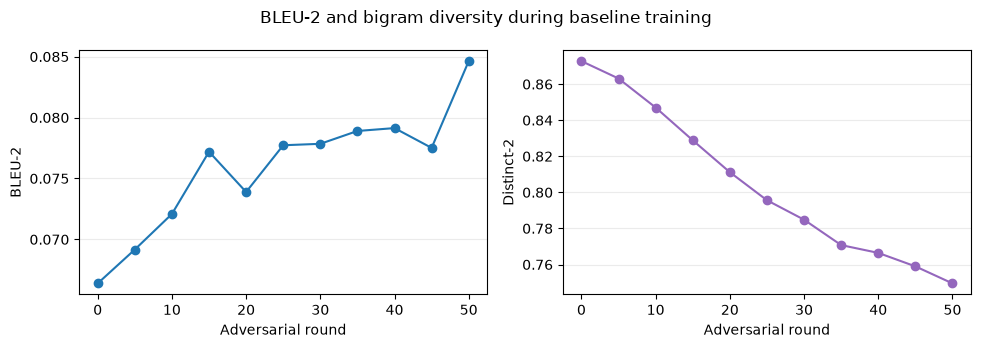

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharex=True)
for ax, metric, color in zip(axes, ['BLEU-2', 'Distinct-2'], ['tab:blue', 'tab:purple']):
    ax.plot(baseline_metrics.index, baseline_metrics[metric], 'o-', color=color)
    ax.set(xlabel='Adversarial round', ylabel=metric)
    ax.grid(axis='y', alpha=0.25)

fig.suptitle('BLEU-2 and bigram diversity during baseline training')
fig.tight_layout()
plt.show()

As shown in the table, Oracle negative log-likelihood (NLL) fell steadily from **9.0884** to **8.7126** over 50 adversarial rounds, meaning the generated tokens were more likely under the Oracle on average. BLEU-2 rose from **0.0664** to **0.0846**, showing more overlap with the training sequences.

Self-BLEU rose from **0.0682** to **0.1281**, so the generated sequences also became more similar to one another. Distinct-2 fell from **0.8728** to **0.7495**, meaning a smaller share of generated token pairs were unique. Together, the scores show a trade-off. The generator produced sequences that scored better against the Oracle and the training data while repeating more of the same patterns.

#### 2. Oracle reference

Oracle reference NLL scores the original training sequences under the Oracle. For BLEU-2, the candidates come from an independent Oracle draw and the references come from the original training data. Self-BLEU uses other sequences from the independent draw. The cell reuses that saved draw when available. Set `REGENERATE_ORACLE_REFERENCE` to repeat sampling directly from the Oracle.

Lower Oracle NLL means the scored sequences have higher average per-token likelihood. Higher BLEU-2 means more overlap with training sequences. Lower Self-BLEU and higher Distinct-2 indicate more diverse output.

In [15]:
reference_file = EVALUATION_DIR / 'oracle_reference.txt'
with tf.Graph().as_default():
    tf.set_random_seed(SEED)
    oracle = build_oracle()
    with tf.Session() as oracle_session:
        oracle_session.run(tf.global_variables_initializer())

        # The original training sequences are the NLL input.
        oracle_loader = Gen_Data_loader(BATCH_SIZE)
        oracle_loader['create_batches'](positive_file)
        ref_nll = target_loss(oracle_session, oracle, oracle_loader)

        # BLEU-2 and Self-BLEU use a separate sample drawn from the Oracle.
        if REGENERATE_ORACLE_REFERENCE or not reference_file.is_file():
            EVALUATION_DIR.mkdir(parents=True, exist_ok=True)
            generate_samples(oracle_session, oracle, BATCH_SIZE, generated_num, reference_file)

ref_bleu2 = compute_bleu2(positive_file, reference_file)
ref_self_bleu = compute_self_bleu(reference_file)
oracle_final = pd.Series(
    [ref_nll, ref_bleu2, ref_self_bleu, ngram_diversity(reference_file, n=2)],
    index=METRIC_COLUMNS,
)
oracle_comparison = pd.DataFrame({
    f'Baseline generator (round {baseline_round})': baseline_final,
    'Oracle reference': oracle_final,
}).T
display(oracle_comparison.round(4))

Instructions for updating:
Use `tf.random.categorical` instead.
Instructions for updating:
Use `tf.cast` instead.


,Oracle NLL,BLEU-2,Self-BLEU,Distinct-2
Baseline generator (round 50),8.7126,0.0846,0.1281,0.7495
Oracle reference,5.7584,0.0767,0.0675,0.8642


The saved baseline scores higher on BLEU-2 than the independent Oracle draw. A generator can increase overlap by concentrating on common patterns in the training references. The baseline's higher Self-BLEU and lower Distinct-2 support that interpretation. A generator could also score lower NLL than the Oracle reference by sampling mainly from high-likelihood modes, since average likelihood rewards those samples regardless of how much of the distribution they cover. Here, the Oracle reference has the lower NLL.

#### 3. Mode collapse detection

The twin axes show Oracle NLL and Self-BLEU on the same baseline rounds. The dashed line marks Self-BLEU for the independent Oracle sample. Distinct-2 is the number of unique bigrams divided by the total number of bigrams.

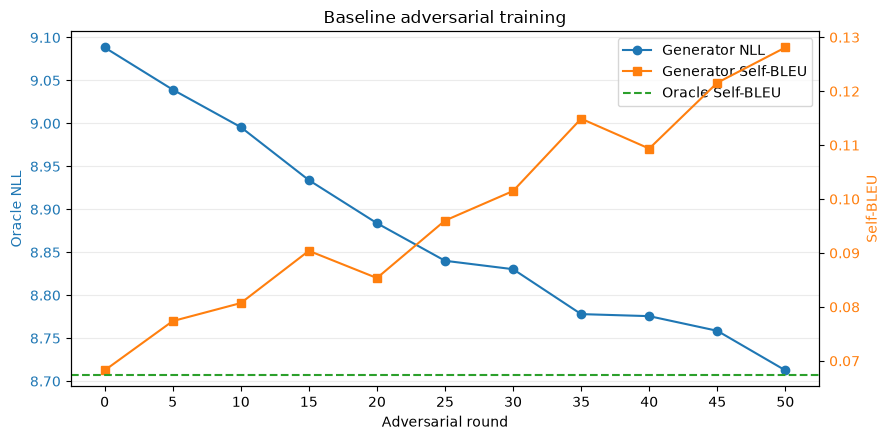

In [16]:
fig, nll_axis = plt.subplots(figsize=(9, 4.5))
bleu_axis = nll_axis.twinx()
rounds = baseline_metrics.index

nll_line, = nll_axis.plot(
    rounds, baseline_metrics['Oracle NLL'], 'o-', color='tab:blue', label='Generator NLL',
)
bleu_line, = bleu_axis.plot(
    rounds, baseline_metrics['Self-BLEU'], 's-', color='tab:orange', label='Generator Self-BLEU',
)
oracle_line = bleu_axis.axhline(
    ref_self_bleu, color='tab:green', linestyle='--', label='Oracle Self-BLEU',
)

nll_axis.set(xlabel='Adversarial round', xticks=rounds, title='Baseline adversarial training')
nll_axis.set_ylabel('Oracle NLL', color='tab:blue')
bleu_axis.set_ylabel('Self-BLEU', color='tab:orange')
nll_axis.tick_params(axis='y', labelcolor='tab:blue')
bleu_axis.tick_params(axis='y', labelcolor='tab:orange')
nll_axis.grid(axis='y', alpha=0.25)
nll_axis.legend(handles=[nll_line, bleu_line, oracle_line])
fig.tight_layout()
plt.show()

In [17]:
def unique_sequence_share(sample_file):
    sequences = [tuple(sequence) for sequence in load_sequences(sample_file)]
    return len(set(sequences)) / len(sequences)


initial_sample = baseline_run / 'eval-round-0.txt'
diversity_comparison = pd.DataFrame({
    'Baseline (round 0)': [baseline_metrics.loc[0, 'Distinct-2'], unique_sequence_share(initial_sample)],
    f'Baseline (round {baseline_round})': [baseline_final['Distinct-2'], unique_sequence_share(baseline_sample)],
    'Oracle reference': [oracle_final['Distinct-2'], unique_sequence_share(reference_file)],
}, index=['Distinct-2', 'Unique sequence share']).T
display(diversity_comparison.round(4))

,Distinct-2,Unique sequence share
Baseline (round 0),0.8728,1.0000
Baseline (round 50),0.7495,0.9976
Oracle reference,0.8642,1.0000


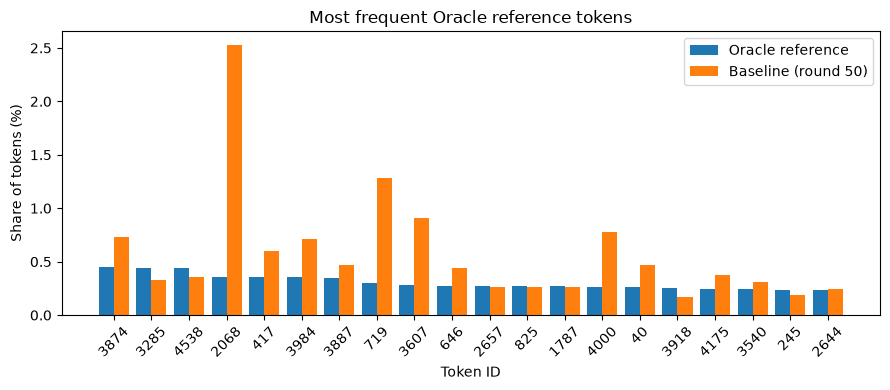

In [18]:
from collections import Counter


def plot_token_distribution(real_file, generated_file, top_k=20):
    real_freq = Counter(token for sequence in load_sequences(real_file) for token in sequence)
    generated_freq = Counter(token for sequence in load_sequences(generated_file) for token in sequence)
    tokens = [token for token, _ in real_freq.most_common(top_k)]
    real_total = real_freq.total()
    generated_total = generated_freq.total()

    x = np.arange(len(tokens))
    width = 0.4
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.bar(x - width / 2, [100 * real_freq[token] / real_total for token in tokens],
           width, label='Oracle reference')
    ax.bar(x + width / 2, [100 * generated_freq[token] / generated_total for token in tokens],
           width, label=f'Baseline (round {baseline_round})')
    ax.set_xticks(x, tokens, rotation=45)
    ax.set(xlabel='Token ID', ylabel='Share of tokens (%)', title='Most frequent Oracle reference tokens')
    ax.legend()
    fig.tight_layout()
    plt.show()


plot_token_distribution(reference_file, baseline_sample)

##### Findings and analysis

**Round 5 was the first measured warning sign in the baseline.** Oracle NLL fell from **9.088** to **9.039**, while Self-BLEU rose from **0.068** to **0.077**, above the Oracle reference of about **0.0675**. In the Lab 2 interpretation matrix, this combination suggests that the generator is producing more likely sequences under the Oracle while repeating more patterns. Distinct-2 also fell from **0.873** to **0.863**, supporting the warning. The five-round evaluation interval leaves the exact onset uncertain.

By round 50, baseline Self-BLEU had reached **0.128** and Distinct-2 had fallen to **0.750**, compared with **0.864** for the Oracle. About **99.8%** of final sequences were still unique. The evidence shows reduced diversity in short patterns, with severe mode collapse unresolved. The Oracle reference table in Task 2 and the plots above show these comparisons.


#### 4. Hyperparameter experiments

Each variant changes one setting from the Lab 2 baseline. The learning-rate variant doubles the generator learning rate from 0.01 to 0.02. The rollout variant reduces Monte Carlo rollouts from 16 to 8. All three saved runs start from the same checkpoint and use the same Oracle training data, training seed (88), 50 rounds, and 9,984 sequences per evaluation. The second table shows each variant's change from the baseline at the final round.

In [19]:
# Change RUN_SEQGAN_ADVERSARIAL to True in the settings to run the adversarial training experiments.
experiment_runs = {'Baseline': baseline_run}
for label, name in [('Double learning rate', 'double_lr'), ('Half the rollouts', 'half_rollouts')]:
    if RUN_SEQGAN_ADVERSARIAL:
        experiment_runs[label] = run_adversarial_training(name, resume_training=RESUME_SEQGAN_TRAINING)
    else:
        experiment_runs[label] = latest_completed_run(EXPERIMENT_RUNS_DIR, f'{name}-')

rows = []
shared_settings = {
    **baseline_config['settings'],
    'tensorflow_seed': baseline_config.get('tensorflow_seed', baseline_config['settings']['seed']),
}
for label, run_dir in experiment_runs.items():
    result = read_run_summary(run_dir)
    settings = result['settings']
    comparison_settings = {
        **settings, 'tensorflow_seed': result.get('tensorflow_seed', settings['seed']),
    }
    if comparison_settings != shared_settings:
        raise ValueError(f'{run_dir.name} and {baseline_run.name} have different shared training settings.')
    rows.append({
        'Configuration': label,
        'Generator LR': result['generator_learning_rate'],
        'Rollouts': result['rollouts'],
        'Round': settings['rounds'],
        'Oracle NLL': result['nll'],
        'BLEU-2': result['bleu2'],
        'Self-BLEU': result['self_bleu'],
        'Distinct-2': result['distinct2'],
        'Run folder': run_dir.name,
    })

hyperparameter_results = pd.DataFrame(rows).set_index('Configuration')
display(hyperparameter_results.round(4))

hyperparameter_changes = hyperparameter_results[METRIC_COLUMNS].subtract(
    hyperparameter_results.loc['Baseline', METRIC_COLUMNS].astype(float), axis='columns',
)
display(hyperparameter_changes.drop(index='Baseline').round(4))

,Generator LR,Rollouts,Round,Oracle NLL,BLEU-2,Self-BLEU,Distinct-2,Run folder
Configuration,,,,,,,,
Baseline,0.01,16,50,8.7126,0.0846,0.1281,0.7495,run-3o4kuzyw
Double learning rate,0.02,16,50,8.6946,0.0840,0.1603,0.6449,double_lr-5mcwj7ex
Half the rollouts,0.01,8,50,8.7830,0.0812,0.1267,0.7452,half_rollouts-fdxc9afu


,Oracle NLL,BLEU-2,Self-BLEU,Distinct-2
Configuration,,,,
Double learning rate,-0.0180,-0.0007,0.0321,-0.1046
Half the rollouts,0.0704,-0.0034,-0.0014,-0.0043


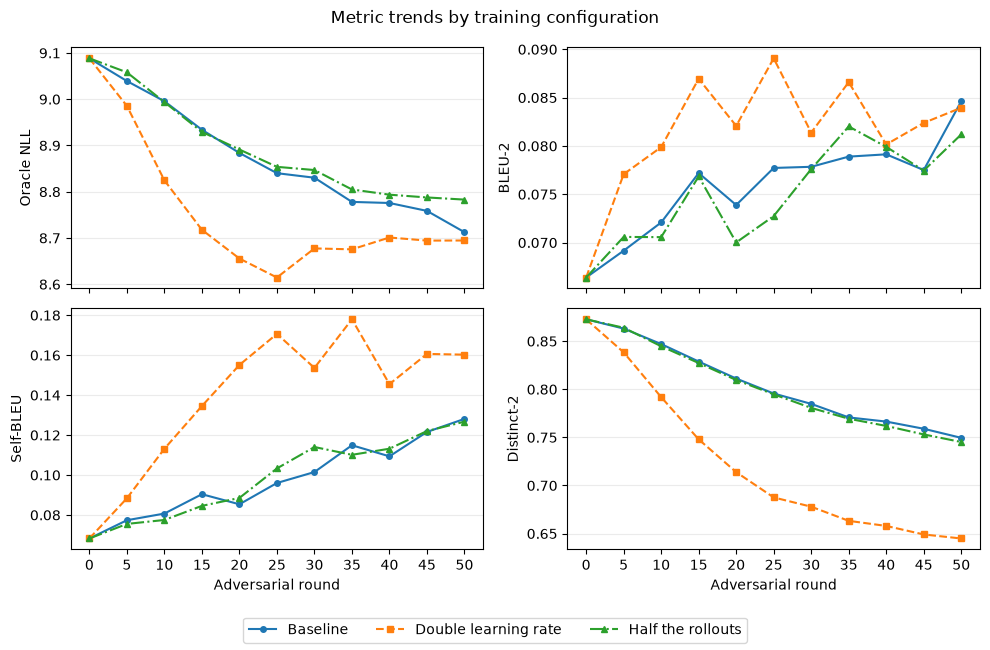

In [20]:
experiment_metrics = {
    label: load_adversarial_metrics(run_dir / EXPERIMENT_LOG.name)
    for label, run_dir in experiment_runs.items()
}

fig, axes = plt.subplots(2, 2, figsize=(10, 6.5), sharex=True)
for ax, metric in zip(axes.flat, METRIC_COLUMNS):
    for (label, metrics), style in zip(experiment_metrics.items(), ['o-', 's--', '^-.']):
        ax.plot(metrics.index, metrics[metric], style, markersize=4, label=label)
    ax.set_ylabel(metric)
    ax.grid(axis='y', alpha=0.25)

for ax in axes[-1]:
    ax.set_xlabel('Adversarial round')
    ax.set_xticks(baseline_metrics.index)

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=3)
fig.suptitle('Metric trends by training configuration')
fig.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()

Both variants also showed their first measured warning sign at **round 5**. NLL and Distinct-2 fell from round 0 while Self-BLEU rose. Doubling the learning rate made the signal stronger early on. At round 5, its Self-BLEU was **0.088** and its Distinct-2 was **0.838**, compared with **0.076** and **0.864** with half the rollouts.

Doubling the learning rate lowered NLL by **0.018** and left BLEU-2 close to baseline. Self-BLEU rose by **0.032** and Distinct-2 fell by **10.46 percentage points**, the clearest sign of increased repetition among the three runs. The small likelihood gain came with a substantial loss of bigram diversity.

Halving the rollouts raised NLL by **0.070** and lowered BLEU-2 by **0.0034**. Self-BLEU fell slightly and Distinct-2 also fell by **0.43 percentage points**, so the diversity metrics give mixed evidence of a small change. The baseline gave the strongest overall balance of quality and diversity in these runs. Each configuration was tested with one training seed.

#### 5. Improving generation diversity

The baseline's loss of bigram diversity motivated trying a higher sampling temperature. We reload the final baseline checkpoint (round 50 in the saved run) and run generation again at temperatures **1.00** and **1.10**, using the same trained weights, seed, and sample count. Temperature changes only how the next token is sampled. Dividing the next-token logits by 1.10 makes less likely tokens easier to sample.

The cell reads the saved comparison for the selected baseline when available. Enable `RUN_TEMPERATURE_COMPARISON` to resample from that checkpoint.

In [21]:
def compare_sampling_temperatures(checkpoint, output_dir, sample_count):
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    rows = []

    for temperature in (1.00, 1.10):
        samples_file = output_dir / f'temperature_{temperature:.2f}.txt'
        # A fresh graph and the same seed give both conditions the same sampling setup.
        with tf.Graph().as_default():
            session, model, oracle, _ = build_seqgan_session(seed=SEED, reset_graph=False)
            with session:
                restore_seqgan_checkpoint(session, model, str(checkpoint))
                likelihood_loader = Gen_Data_loader(BATCH_SIZE)
                nll, bleu2, self_bleu = eval_func(
                    session, model, oracle, likelihood_loader,
                    BATCH_SIZE, sample_count, positive_file, samples_file,
                    temperature=temperature,
                )

        rows.append({
            'Temperature': temperature,
            'Oracle NLL': float(nll),
            'BLEU-2': bleu2,
            'Self-BLEU': self_bleu,
            'Distinct-2': ngram_diversity(samples_file, n=2),
        })

    results = pd.DataFrame(rows)
    results.to_csv(output_dir / 'comparison.csv', index=False)
    return results


diversity_checkpoint = baseline_run / Path(FINAL_CKPT).name
temperature_dir = baseline_run / 'temperature-comparison'
temperature_csv = temperature_dir / 'comparison.csv'
# The original comparison was exported before results were stored per run.
if not temperature_csv.is_file() and baseline_run.name == 'run-3o4kuzyw':
    temperature_csv = SAVE_DIR / 'temperature-comparison' / 'comparison.csv'

if RUN_SEQGAN_ADVERSARIAL or RUN_TEMPERATURE_COMPARISON or not temperature_csv.is_file():
    temperature_results = compare_sampling_temperatures(diversity_checkpoint, temperature_dir, generated_num)
else:
    temperature_results = pd.read_csv(temperature_csv)

temperature_results = temperature_results.set_index('Temperature')
display(temperature_results.round(4))
display((temperature_results.loc[1.10] - temperature_results.loc[1.00])
        .rename('Change at 1.10 vs 1.00').to_frame().T.round(4))

,Oracle NLL,BLEU-2,Self-BLEU,Distinct-2
Temperature,,,,
1.0,8.7250,0.0784,0.1104,0.7494
1.1,9.0073,0.0720,0.0859,0.8104


,Oracle NLL,BLEU-2,Self-BLEU,Distinct-2
Change at 1.10 vs 1.00,0.2823,-0.0064,-0.0246,0.0611


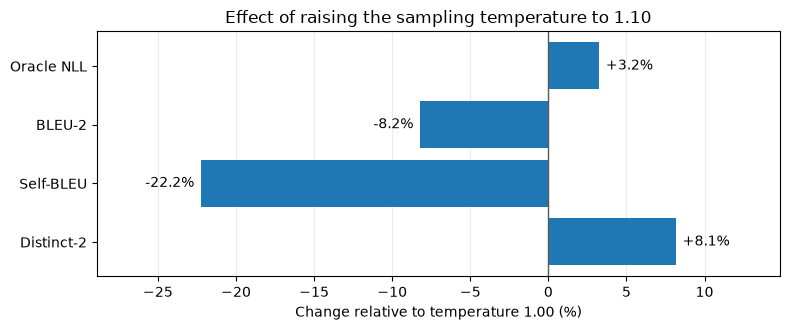

In [22]:
temperature_change_pct = (
    temperature_results.loc[1.10, METRIC_COLUMNS]
    .div(temperature_results.loc[1.00, METRIC_COLUMNS])
    .sub(1)
    .mul(100)
)

fig, ax = plt.subplots(figsize=(8, 3.4))
bars = ax.barh(temperature_change_pct.index, temperature_change_pct, color='tab:blue')
ax.bar_label(bars, labels=[f'{value:+.1f}%' for value in temperature_change_pct], padding=5)
ax.axvline(0, color='0.35', linewidth=1)
ax.set(xlabel='Change relative to temperature 1.00 (%)', title='Effect of raising the sampling temperature to 1.10')
ax.invert_yaxis()
ax.margins(x=0.22)
ax.set_axisbelow(True)
ax.grid(axis='x', alpha=0.25)
fig.tight_layout()
plt.show()

Compared with fresh samples at **1.00**, sampling at **1.10** lowered Self-BLEU by **0.0246** and raised Distinct-2 from about **74.94%** to **81.04%**. Using the unrounded scores, that's a gain of **6.11** percentage points, or **8.1%** relative to the starting score, as shown in the graph. Both changes indicate less repetition. Oracle NLL rose by **0.282** and BLEU-2 fell by **0.0064**, indicating lower Oracle likelihood and less overlap with the training data. The higher temperature improved diversity with a quality cost in this run. With one sampling seed, it is unclear whether the size of that trade-off would hold across seeds.